# 第 1 章 PyOD｜一条主线讲透 11 个异常检测算法


### 0.0 PyOD 是什么 & 本章 11 个算法从哪来

**PyOD（Python Outlier Detection）**：2017 年建立、JMLR 2019 发表的**异常检测专用库**；PyOD 3 含 **61 个检测器**，覆盖表格 / 时序 / 图 / 文本 / 图像 / 音频（完整模块地图见附录）。本章只讲**表格（Tabular）**场景。

**它解决的问题**：没标签、异常极少时，把少数「异样点」**排到最前面**。输出的是**连续异常分数**而不是硬结论——「正常 / 异常」由你按业务阈值去切。

**统一接口**：全库所有检测器的 API 长得一样，这也是本章 11 个算法能共用同一套 `diagnose` 实验模板的前提——

> `fit(X)` 训练（从不接触标签）→ `decision_function(X)` 连续分数（**越大越异常**）→ `predict(X)` 0/1 结论；训练后可取 `decision_scores_` / `labels_`。
>
> 📌 `contamination` 只决定 `predict` 的切分阈值，**不改分数排序**。

**官方按实现机制把检测器分 7 类**，本章精讲的 11 个用 ⭐ 标出：

| 官方 Type（7 类） | 一句话说明 | 本章精讲 ⭐（括号内为同类其他算法） |
| :--- | :--- | :--- |
| `Probabilistic` | 概率 / 密度估计 | ⭐ECOD、⭐HBOS（另有 COPOD、ABOD、KDE、GMM 等） |
| `Linear Model` | 线性 / 边界模型 | ⭐OCSVM（另有 PCA、MCD 等） |
| `Proximity-Based` | 近邻 / 邻近度 | ⭐KNN、⭐LOF、⭐COF、⭐CBLOF、⭐SOD（另有 LOCI、ROD 等） |
| `Outlier Ensembles` | 随机化 + 集成 | ⭐IForest、⭐LODA（另有 DIF、XGBOD 等） |
| `Neural Networks` | 深度模型 | ⭐AutoEncoder（另有 VAE、DeepSVDD 等） |
| `Graph / Embedding` | 图 / 嵌入 | 本章不涉及（R-Graph、LUNAR 等） |
| `combination` | **分数融合，不是检测器** | 附录 A 用（average / AOM / MOA） |

**两套分类，别混**：官方 7 类是「**检索用的模块地图**」，本章 4 族是「**讲解用的原理主线**」，同一个算法两边可能落位不同。典型差异：HBOS 官方归 `Proximity-Based`，按打分原理归本章 **Ⅰ 族**；OCSVM 官方归 `Linear Model`，按「学出正常边界」归 **Ⅳ 族**。全章只沿一条分类轴推进：**「正常模型怎么定义」**——这正是下一节 0.2 的四族地图。

> 💡 选取标准：这 11 个里每个都对「正常模型」有一套清晰的原理定义，且都能用同一套 `diagnose` 模板做专属实验。

---


## 📊 本章交互图解（浏览器新标签打开）

> 每个算法都配一份可交互的原理图解：分步拆解、SVG 示意、专属数据实测分数。点开即在浏览器新标签中展开，不打断阅读主线。

- **§1.1** ECOD：[<a href="http://127.0.0.1:5500/html/ECOD图解.html" target="_blank">👉 在浏览器打开 ECOD图解</a>](http://127.0.0.1:5500/html/ECOD图解.html)
- **§1.2** HBOS：[<a href="http://127.0.0.1:5500/html/HBOS图解.html" target="_blank">👉 在浏览器打开 HBOS图解</a>](http://127.0.0.1:5500/html/HBOS图解.html)
- **§2.1** KNN：[<a href="http://127.0.0.1:5500/html/PyOD.KNN.原理图解.html" target="_blank">👉 在浏览器打开 KNN原理图解</a>](http://127.0.0.1:5500/html/PyOD.KNN.原理图解.html)
- **§2.2** LOF：[<a href="http://127.0.0.1:5500/html/PyOD.LOF.原理图解.html" target="_blank">👉 在浏览器打开 LOF原理图解</a>](http://127.0.0.1:5500/html/PyOD.LOF.原理图解.html)
- **§2.3** COF：[<a href="http://127.0.0.1:5500/html/PyOD.COF.原理图解.html" target="_blank">👉 在浏览器打开 COF原理图解</a>](http://127.0.0.1:5500/html/PyOD.COF.原理图解.html)
- **§2.4** CBLOF：[<a href="http://127.0.0.1:5500/html/PyOD.CBLOF.原理图解.html" target="_blank">👉 在浏览器打开 CBLOF原理图解</a>](http://127.0.0.1:5500/html/PyOD.CBLOF.原理图解.html)
- **§2.5** SOD：[<a href="http://127.0.0.1:5500/html/PyOD.SOD.原理图解.html" target="_blank">👉 在浏览器打开 SOD原理图解</a>](http://127.0.0.1:5500/html/PyOD.SOD.原理图解.html)
- **§3.1** IForest：[<a href="http://127.0.0.1:5500/html/PyOD.IForest.原理图解.html" target="_blank">👉 在浏览器打开 IForest原理图解</a>](http://127.0.0.1:5500/html/PyOD.IForest.原理图解.html)
- **§3.2** LODA：[<a href="http://127.0.0.1:5500/html/PyOD.LODA.原理图解.html" target="_blank">👉 在浏览器打开 LODA原理图解</a>](http://127.0.0.1:5500/html/PyOD.LODA.原理图解.html)
- **§4.1** OCSVM：[<a href="http://127.0.0.1:5500/html/PyOD.OCSVM.原理图解.html" target="_blank">👉 在浏览器打开 OCSVM原理图解</a>](http://127.0.0.1:5500/html/PyOD.OCSVM.原理图解.html)
- **§4.2** AutoEncoder：[<a href="http://127.0.0.1:5500/html/PyOD.AutoEncoder.原理图解.html" target="_blank">👉 在浏览器打开 AutoEncoder原理图解</a>](http://127.0.0.1:5500/html/PyOD.AutoEncoder.原理图解.html)

- **附** 11 套专属诊断数据一次看完：[<a href="http://127.0.0.1:5500/html/PyOD.诊断性数据图解.html" target="_blank">👉 在浏览器打开 诊断性数据图解</a>](http://127.0.0.1:5500/html/PyOD.诊断性数据图解.html)


## 本章导读

> $$\text{score}(x)=\text{dist}\big(x,\ \mathcal{M}_{\text{normal}}\big)$$
>
> **全章只有一条主线**：先给「正常」下定义，再把样本**偏离这个定义的程度**量化成异常分数。
> 四大原理族 = 「正常模型」的**四种定义**；后一族专门补前一族的破口。

| 主线四步 | Ⅰ 分布 | Ⅱ 邻近 | Ⅲ 隔离 | Ⅳ 边界 / 重构 |
| :--- | :--- | :--- | :--- | :--- |
| **正常 =** | 各维高概率区 | 邻居密集 | *不定义* | 紧凑边界 / 低维流形 |
| **分数 =** | $-\log P(x)$ | 距离 / 密度比 | 隔离路径长度 | 边距 / 重构误差 |
| **破口 →** | 看不见特征组合 | $O(n^2)$、高维失效 | 偏离度量靠手工 | *（终点）* |

- **怎么读**：`0.0` 先认识 PyOD，`0.1~0.3` 三节讲清主线 → 实验准备整段运行 → 四族依次推进 → 族小结回扣破口链。
- **每节只问三句**：正常定义成什么？这个假设何时破？下一族怎么补？
- **一算法一数据（本章铁律）**：每种算法针对的情况不同，**每节的实验只用为该算法量身定做的专属数据**；没有任何一个「通用数据集」贯穿正文。
- **附录不是主线**：公共基准数据、分数融合、utils、工程化、选型、思考题一律放在最后，按需查阅。
- 公式、代码、专属数据图**全在本课件内**，不依赖其他文件。

---


## 0. 一条主线（全章骨架）

### 0.1 主线：所有算法都在算同一个东西

把 PyOD 的十几个算法拆开看，它们的 API 几乎一样：`fit(X)` → `decision_function(X)`。**差别只在一个地方**：

$$
\text{score}(x) = \text{dist}\Big(x,\ \underbrace{\mathcal{M}_{\text{normal}}}_{\text{「正常」的模型}}\Big)
$$

| 关键问题 | 含义 |
| :--- | :--- |
| $\mathcal{M}_{normal}$ 是什么？ | **每一族算法的分水岭**：分布？邻居？随机切分？低维流形？ |
| 在哪个尺度上比？ | 全局 / 局部 / 子空间 / 单个特征 |
| 怎么把「偏离」变成数？ | 负对数似然、距离、密度比、路径长度、重构误差 |

> 📌 **本章不是「介绍 10 个 API」，而是沿「正常模型从最简单到最复杂」走四步。**
> 每学一族，只问三句：① 它假设正常数据长什么样？② 这个假设什么时候会破？③ 下一族怎么补上这个破口？
> 这三条会在**每一节开头**以「主线定位」的形式重复出现，随时可以对齐进度。


### 0.2 四族地图：正常模型的四种定义

| 族 | 「正常」的定义 | 「异常」的定义 | 分数从哪来 | 看数据的尺度 | 本章算法 |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Ⅰ 分布与概率密度** | 每个特征的高概率区 | 落在分布尾部 = 小概率事件 | $-\log P(x)$ | 单维 / 全局 | ECOD、HBOS |
| **Ⅱ 邻近度与局部几何** | 邻居密集、密度与周围一致 | 离群、比邻居稀疏 | 距离 / 局部密度比 | 局部邻域 → 簇 → 子空间 | KNN、LOF、COF、CBLOF、SOD |
| **Ⅲ 随机隔离与集成** | *不定义正常* | 用很少的随机切分就能被孤立 | 平均路径长度 / 投影似然 | 全局随机子样本 | IForest、LODA |
| **Ⅳ 边界与重构** | 落在紧凑边界内 / 能被低维结构还原 | 掉到边界外 / 还原不了 | 到边界距离 / 重构误差 | 全局流形 | OCSVM、AutoEncoder |

**破口链 —— 这就是四族的递进顺序**：

1. **Ⅰ → Ⅱ**：Ⅰ 族把每个特征当独立变量，看不见**特征之间的组合关系**；Ⅱ 族丢掉分布假设，改用样本之间的几何关系。
2. **Ⅱ → Ⅲ**：Ⅱ 族要算两两距离，$O(n^2)$ 且高维失效；Ⅲ 族**范式反转** —— 异常「稀少且不同」，干脆不刻画正常，直接去隔离它。
3. **Ⅲ → Ⅳ**：前三族都是手工定义偏离度量；Ⅳ 族让模型自己**学出**正常的边界或低维流形，用「学不会 / 还原不了」当分数。

> ⚠️ 只有一条分类轴：**「正常模型怎么定义」**。树、神经网络、直方图都只是族内的实现细节，不单独成章。

---


### 0.3 递进：假设越来越弱，模型越来越强

| 维度 | Ⅰ 分布 | Ⅱ 邻近 | Ⅲ 隔离 | Ⅳ 边界 / 重构 |
| :--- | :--- | :--- | :--- | :--- |
| 需要分布假设 | 强（边际独立） | 无 | 无 | 无 |
| 需要特征缩放 | ❌ | ✅ 必须 | ❌ | ✅ 必须 |
| 捕捉特征相关性 | ❌ | ✅（隐式） | ✅（随机子空间） | ✅✅ |
| 时间复杂度 | $O(nd)$ | $O(n^2d)$ | $O(t\psi\log\psi)$ | $O(E\cdot nd)$ |
| 高维表现 | 好 | 差（维度灾难） | 好 | 好 |
| 可解释性 | 高（能指到具体特征） | 中（能指到邻居） | 低 | 低 |

> 读表方法：**没有「最好的算法」，只有「假设与数据最匹配的算法」**。族与族是「补破口」，不是「谁取代谁」。

**数据约定（一句话版）**：

- **正文 = 一算法一套专属数据**：每种算法针对的情况不同，各算法节的实验**只用为本节量身定做的诊断数据**（`make_diagnostic_cases()`，见实验准备）。
- **公共基准数据**只有一份（单高斯），**不进正文**；仅供附录 A 的分数融合使用 —— 融合必须同数据、同尺度，这是它存在的唯一理由。
- **不比 AUC**：专属数据只回答「原理是否成立」—— 看「考察点」是否排到正常点 P95 之上。

---


> 🛠️ **实验准备**（下面几格是基础设施，**不属于主线章节**，可整段运行后跳过）
> - 依次是：导入与绘图配置 → 11 套专属诊断数据与 `diagnose` 工具 → 形状预览 → 公共基准数据（仅附录用）。
> - 所有代码必须在进入第一族前运行一次；它们不参与「正常模型」的讨论。


In [1]:
# --- 导入基础库并配置绘图环境 ---
import numpy as np                                              # 数值计算
import pandas as pd                                             # 数据处理
import matplotlib.pyplot as plt                                 # 绘图
from matplotlib.colors import ListedColormap                    # 自定义颜色映射
import warnings                                                 # 警告控制模块

warnings.filterwarnings('ignore')                               # 静默警告，输出更干净

FONTS = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']           # 中文字体
plt.rcParams['font.sans-serif'] = FONTS                         # 不配字体中文会成方块
plt.rcParams['axes.unicode_minus'] = False                      # 负号正常显示

np.random.seed(42)                                              # 固定种子，结果可复现

print("绘图环境就绪")                                           # 环境就绪提示

绘图环境就绪


> 🎯 **本章的实验数据：一算法一套专属小题**（形状照着每个算法的关键假设设计）。
> - `make_diagnostic_cases()` 确定性生成，不用随机数发生器，重跑形状不变。
> - 各算法节用 `diagnose(..., plot=True)` 画出这套点（蓝=正常，红=考察点），打分结果打印在图上方。
> - **不比 AUC**：只看「考察点」有没有排到正常点 P95 之上。

In [2]:
# --- 实验准备：11 套专属诊断数据，每套只考一条假设 ---
def make_diagnostic_cases():                                    # 构造 11 套诊断数据
    """11 套按算法定制的数据，每套只考一条关键假设。

    全部确定性构造，不调用随机数发生器：
    抖动由整数哈希 + Box-Muller 生成，并截断到 ±2.8σ。
    换机器、换版本，形状与「考察点」都不变。
    key 即算法名，如 CASES['ECOD']。
    """
    import math                                                 # 数学：sin / log / sqrt / cos
    TAU = 2.0 * math.pi                                         # 一整个圆 = 2π

    def u(i, salt):                                             # 均匀伪随机数 → [0, 1)
        t = math.sin((i + 1) * 12.9898                          # 整数哈希：线性部分
                     + salt * 78.233) * 43758.5453              # 再乘大数放大误差
        return t - math.floor(t)                                # 取小数部分 → [0, 1)

    def g(i, salt):                                             # 标准正态抖动 g(i, salt)
        r2 = -2.0 * math.log(max(u(i, salt), 1e-6))             # Box-Muller：-2·ln U1
        th = TAU * u(i, salt + 37.0)                            # Box-Muller：角度 2π·U2
        z = math.sqrt(r2) * math.cos(th)                        # 半径 × cos(角度) → 正态数
        return max(-2.8, min(2.8, z))                           # 截断到 ±2.8σ

    def blob(cx, cy, sd, n, salt):                              # 团：中心 / σ / 点数 / 种子
        pts = []                                                # 收集 n 个点
        for i in range(n):                                      # 逐点生成
            x = cx + sd * g(i, salt)                            # x 方向抖动
            y = cy + sd * g(i, salt + 1)                        # y 方向抖动
            pts.append([x, y])                                  # 拼成一个点
        return pts                                              # 返回点列表

    def band(rho, k, n, salt):                                  # 相关云：y = rho·x + k·ε
        pts = []                                                # 收集 n 个点
        for i in range(n):                                      # 逐点生成
            x = g(i, salt)                                      # x 取标准正态
            y = rho * x + k * g(i, salt + 1)                    # 线性相关 + 独立噪声
            pts.append([x, y])                                  # 拼成一个点
        return pts                                              # 返回点列表

    def sod_cloud(n):                                           # SOD 专用：2 维相关 + 8 维噪声
        rows = []                                               # 收集 n 个 10 维点
        for i in range(n):                                      # 逐点生成
            x = g(i, 7)                                         # 相关子空间的 x
            row = [x, x + .50 * g(i, 8)]                        # y ≈ x，中等相关
            row += [2.0 * g(i, 9 + j) for j in range(8)]        # 后 8 维大方差
            rows.append(row)                                    # 拼成一个 10 维点
        return rows                                             # 返回点列表

    C = {}                                                      # 11 套数据的总容器

    # ECOD：普通相关云 y ≈ 0.5x，异常点只在斜方向上破坏「组合」
    C['ECOD'] = dict(                                           # Ⅰ 族：椭圆云 + 组合异常
        X=band(0.5, 0.866, 220, 1),                             # 220 点，相关系数 ≈ 0.6
        A=[[1.6, -1.6], [-1.6, 1.6],                            # 两个对角组合点
           [1.5, -1.4], [-1.4, 1.5]])                           # 两个轻微偏移组合点

    # HBOS：左下 / 右上双团，异常点两维都在最密 bin，组合却从未出现
    h1 = blob(-1.8, -1.8, .35, 110, 10)                         # 左下团：中心 (-1.8, -1.8)
    h2 = blob(1.8, 1.8, .35, 110, 12)                           # 右上团：中心 (1.8, 1.8)
    hb_a = [[-1.8, 1.8], [1.8, -1.8]]                           # 跨团对角的两个组合异常
    C['HBOS'] = dict(X=h1 + h2, A=hb_a)                         # 双团拼接 + 对角组合

    # KNN：双密度簇，考察点全是「稀疏簇里的普通点」
    tight = blob(-2.2, 0.0, .35, 180, 3)                        # 密集簇：180 点，σ=0.35
    loose = blob(2.4, 0.0, 1.5, 10, 5)                          # 稀疏簇：10 点，σ=1.5
    knn_a = [[2.4, 0.], [2.0, 1.0], [3.1, -.6]]                 # 稀疏簇里 3 个普通点
    C['KNN'] = dict(X=tight + loose, A=knn_a)                   # 等着被误报

    # LOF：更极端的密度反差，再补 1 个紧贴密簇边缘的孤点
    tight4 = blob(-2.4, 0.0, .28, 200, 40)                      # 密集簇：200 点，σ=0.28
    loose4 = blob(2.6, 0.0, 1.6, 100, 42)                       # 稀疏簇：100 点，σ=1.6
    lof_a = [[2.6, 0.], [2.4, 1.2], [-1.75, 0.]]                # 2 个稀疏点 + 1 边缘点
    C['LOF'] = dict(X=tight4 + loose4, A=lof_a)                 # 极端密度反差

    # COF：密集团 + 弯曲链（取自链式流形经典例题）+ 远处孤点
    cluster = [                                                 # 15 点密集团
        [1.0, 1.2], [1.5, .9], [2.1, 1.1], [2.6, .9],           # 第 1 排
        [1.2, 1.9], [1.8, 2.0], [2.4, 1.8], [2.9, 1.6],         # 第 2 排
        [1.0, 2.7], [1.7, 2.8], [2.4, 2.7], [3.1, 2.5],         # 第 3 排
        [1.6, 3.5], [2.4, 3.6], [3.0, 3.3]]                     # 第 4 排
    chain = [                                                   # 10 点弯曲队伍
        [4.6, 3.6], [5.8, 3.9], [7.0, 4.5],                     # 链的前 3 点
        [8.1, 5.2], [9.1, 6.1], [9.9, 7.1],                     # 链的中段 3 点
        [10.5, 8.2], [10.9, 9.4],                               # 链的后段 2 点
        [11.1, 10.7], [11.0, 12.0]]                             # 链的末端 2 点
    C['COF'] = dict(X=cluster + chain,                          # 团 + 链 = 正常点
                    cluster=cluster, chain=chain,               # 原样再存一份（画图用）
                    A=[[.5, -3.5]])                             # 链末端外的孤点

    # CBLOF：大 / 中 / 小三簇，专门考「按规模分大小簇」这条规则
    b6 = blob(0.0, 0.0, .55, 180, 50)                           # 大簇：180 点，中心原点
    m6 = blob(3.0, 2.6, .40, 45, 52)                            # 中簇：45 点，中心 (3.0, 2.6)
    s6 = blob(-3.2, 3.0, .18, 12, 54)                           # 小簇：12 点，中心 (-3.2, 3.0)
    cb_a = [[-3.2, 3.0], [0., 3.2]]                             # 小簇中心 + 画面上方远处点
    C['CBLOF'] = dict(X=b6 + m6 + s6, A=cb_a)                   # 三簇拼接

    # SOD：前两维强相关，另外 8 维是大方差噪声
    noise = [1.9 * g(j + 1, 61) for j in range(8)]              # 噪声维取典型值
    sod_a = [[0, 3.5] + noise]                                  # 相关子空间里偏到 (0, 3.5)
    C['SOD'] = dict(X=sod_cloud(220), A=sod_a)                  # 子空间 + 噪声维

    # IForest：大团 + 远处 7 点抱团小簇（不孤立，密度法容易漏）
    big8 = blob(0.0, 0.0, .55, 220, 20)                         # 大团：220 点，σ=0.55
    small8 = blob(3.4, 3.0, .16, 7, 22)                         # 远处小簇：7 点，σ=0.16
    C['IForest'] = dict(X=big8, A=small8,                       # X / 考察点
                        S=small8)                               # S：小簇坐标再存一份

    # LODA：各向同性高斯团 + 角落点 (1.8, 1.8)
    iso = [[g(i, 36), g(i, 37)] for i in range(220)]            # 各向同性高斯团
    C['LODA'] = dict(X=iso, A=[[1.8, 1.8]])                     # 单维 1.8σ 不极端，斜向才显形

    # OCSVM：细环，中心是空的；环心与环外各放一个点
    X10 = []                                                    # 收集 240 个环上的点
    for i in range(240):                                        # 逐点生成
        th = TAU * u(i, 32)                                     # 角度均匀铺满圆周
        R = 2.6 + .10 * g(i, 33)                                # 半径 2.6±0.10 → 细环
        X10.append([R * math.cos(th),                           # 极坐标 → 直角坐标 x
                    R * math.sin(th)])                          # 极坐标 → 直角坐标 y
    oc_a = [[0., 0.], [4.2, 0.]]                                # 环心 + 环外各 1 个点
    C['OCSVM'] = dict(X=X10, A=oc_a)                            # 环形 + 中心空洞

    # AutoEncoder：一维 sin 流形，异常点落在曲线外
    X11 = []                                                    # 收集 220 个曲线上的点
    for i in range(220):                                        # 逐点生成
        t = -3.2 + 6.4 * u(i, 34)                               # 参数 t 均匀铺在 [-3.2, 3.2]
        X11.append([t, math.sin(t) + .07 * g(i, 35)])           # 曲线 ± 微抖动
    ae_a = [[0, 2.3], [1.6, -1.8], [-2.2, 2.0]]                 # 3 个曲线外的点
    C['AE'] = dict(X=X11, A=ae_a)                               # sin 流形
    return C                                                    # 返回 11 套数据字典


_RAW = make_diagnostic_cases()                                  # 生成 11 套原始数据（纯列表）
CASES = {}                                                      # 正式容器：换成 numpy 数组
for _k, _v in _RAW.items():                                     # 逐套转换
    _d = {'X': np.asarray(_v['X'], dtype=float),                # 正常点 → float 数组
          'A': np.asarray(_v['A'], dtype=float)}                # 考察点 → float 数组
    for _e in ('cluster', 'chain', 'S'):                        # 可选附加键
        if _e in _v:                                            # 只有部分套才带
            _d[_e] = np.asarray(_v[_e], dtype=float)            # 附加键也转数组
    CASES[_k] = _d                                              # 存回正式容器

CASE_ORDER = ['ECOD', 'HBOS', 'KNN', 'LOF',                     # Ⅰ 族 + Ⅱ 族前半
              'COF', 'CBLOF', 'SOD', 'IForest',                 # Ⅱ 族后半 + Ⅲ 族
              'LODA', 'OCSVM', 'AE']                            # Ⅲ 族 + Ⅳ 族

CASE_NAMES = {                                                  # 每套数据的一句话标签
    'ECOD': '椭圆云+组合异常',                                  # Ⅰ 族：云 + 斜向组合
    'HBOS': '双团+密bin组合',                                   # Ⅰ 族：双团 + 同 bin 组合
    'KNN': '双密度簇',                                          # Ⅱ 族：一密一疏两簇
    'LOF': '密度反差+边缘孤点',                                 # Ⅱ 族：更极端的密度反差
    'COF': '密集团+弯曲链',                                     # Ⅱ 族：团 + 弯曲队伍
    'CBLOF': '大中小三簇',                                      # Ⅱ 族：三簇规模差异
    'SOD': '子空间+噪声维',                                     # Ⅱ 族：相关子空间 + 噪声
    'IForest': '大团+远处小簇',                                 # Ⅲ 族：大团 + 远处小簇
    'LODA': '高斯团+角落点',                                    # Ⅲ 族：高斯团 + 斜角点
    'OCSVM': '环形+中心空洞',                                   # Ⅳ 族：细环 + 中心空洞
    'AE': 'sin 流形'}                                           # Ⅳ 族：一维 sin 曲线


def _plot_diagnostic(key, name):                                # 内部函数：画单套专属数据
    """画出这套数据：蓝点=正常，红点=考察点。"""
    import matplotlib.pyplot as plt                             # 局部导入绘图库
    X2 = np.asarray(CASES[key]['X'], dtype=float)[:, :2]        # 正常点前两维
    A2 = np.asarray(CASES[key]['A'], dtype=float)[:, :2]        # 考察点前两维
    fig, ax = plt.subplots(figsize=(6.4, 5.0))                  # 新建画布
    pad = .45                                                   # 坐标轴四周留白
    xs, ys = X2[:, 0], X2[:, 1]                                 # 正常点的两列坐标
    xmin, xmax = xs.min() - pad, xs.max() + pad                 # x 范围（外扩 pad）
    ymin, ymax = ys.min() - pad, ys.max() + pad                 # y 范围（外扩 pad）
    if A2.size:                                                 # 有考察点时一并纳入范围
        xmin = min(xmin, A2[:, 0].min() - pad)                  # x 下界外扩
        xmax = max(xmax, A2[:, 0].max() + pad)                  # x 上界外扩
        ymin = min(ymin, A2[:, 1].min() - pad)                  # y 下界外扩
        ymax = max(ymax, A2[:, 1].max() + pad)                  # y 上界外扩
    if key == 'COF':                                            # COF 区分「团」与「链」
        ax.plot(X2[15:, 0], X2[15:, 1],                         # 链：x / y
                color='#0E9F8E', alpha=.35, lw=6)               # 青色粗线显示队形
        ax.scatter(X2[:15, 0], X2[:15, 1],                      # 密集团：x / y
                   s=30, c='#2E6FE8', label='密集团',           # 大小 / 蓝 / 图例
                   zorder=3)                                    # 压在网格之上
        ax.scatter(X2[15:, 0], X2[15:, 1],                      # 细长队伍：x / y
                   s=30, c='#0E9F8E', label='细长队伍',         # 大小 / 青
                   zorder=3)                                    # 压在网格之上
    else:                                                       # 其余 10 套统一画法
        ax.scatter(X2[:, 0], X2[:, 1],                          # 正常点：x / y
                   s=14, c='#2E6FE8', alpha=.7,                 # 小点 / 蓝 / 半透明
                   label='正常点', zorder=3)                    # 图例名 / 压网格上
    ax.scatter(A2[:, 0], A2[:, 1], s=78,                        # 考察点：x / y / 点大小
               c='#E0574C', edgecolors='white',                 # 红色 + 白色描边
               linewidths=1.2, label='考察点',                  # 描边宽 / 图例名
               zorder=5)                                        # 画在最上层
    ax.set_xlim(xmin, xmax)                                     # 应用 x 范围
    ax.set_ylim(ymin, ymax)                                     # 应用 y 范围
    sub = '看红点分数是否越过 P95（结果见上方输出）'            # 副标题：读图提示
    ax.set_title('%s 专属数据 · %s' % (key, name)               # 主标题：算法 + 标签
                 + chr(10) + sub, fontsize=11)                  # 换行后接副标题
    handles, labels = ax.get_legend_handles_labels()            # 收集图例句柄与标签
    fig.legend(handles, labels, loc='lower center',             # 图例：底部居中
               bbox_to_anchor=(.5, .015),                       # 稍微贴底
               ncol=len(labels), fontsize=8.5,                  # 单行横排 / 字号
               frameon=False, handletextpad=.35,                # 无边框 / 项间距
               columnspacing=2.2, borderaxespad=0)              # 列间距 / 不压边
    fig.subplots_adjust(left=.09, right=.97,                    # 左右留白
                        top=.83, bottom=.17)                    # 上下给标题图例留位
    plt.show()                                                  # 渲染显示


def diagnose(model, key, name,                                  # 对外入口：模型 / 键 / 名称
             scale=False, plot=False, joint=False):             # 缩放 / 画图 / 整批
    """不比 AUC：只看红点有没有排到正常点 P95 之上。

    plot=True 时画出这套专属数据（蓝=正常，红=考察点）。
    joint=True 供 COF / SOD 用：这两个算法按「传入集合本身」
    算分（近邻在集合内部找），不能只给一两个点打分，所以把
    红点并入正常点整批打分后再拆开对比。
    """
    Xc = np.asarray(CASES[key]['X'], dtype=float)               # 本套正常点
    Ac = np.asarray(CASES[key]['A'], dtype=float)               # 本套考察点
    scaler = None                                               # 默认不做缩放
    if scale:                                                   # 按需做标准化 / 归一化
        from sklearn.preprocessing import MinMaxScaler          # 归一化
        from sklearn.preprocessing import StandardScaler        # 标准化
        if scale == 'minmax':                                   # 要求归一化到 [0, 1]
            scaler = MinMaxScaler()                             # 选 MinMax
        else:                                                   # 其他情况一律标准化
            scaler = StandardScaler()                           # 选 Standard
        Xc = scaler.fit_transform(Xc)                           # 只在正常点上 fit
        Ac = scaler.transform(Ac)                               # 考察点只 transform
    try:                                                        # 容错：个别算法 / 参数可能报错
        model.fit(Xc)                                           # 在正常点上训练
        if joint:                                               # 「集合内部」打分的算法
            both = np.vstack([Xc, Ac])                          # 正常点 + 考察点整批
            s_all = model.decision_function(both)               # 整批打分
            s_all = np.asarray(s_all)                           # 统一转成数组
            s_norm = s_all[:len(Xc)]                            # 拆出正常点分数
            s_anom = s_all[len(Xc):]                            # 拆出考察点分数
        else:                                                   # 常规算法：分开打分
            s_norm = model.decision_function(Xc)                # 正常点分数
            s_anom = model.decision_function(Ac)                # 考察点分数
    except Exception as e:                                      # 单套失败不影响整章
        bad = ("[%s·专属] %-11s | 当前版本/参数下"              # 失败提示（前段）
               "未能完成: %s: %s")                              # 失败提示（后段）
        print(bad % (key, name, type(e).__name__, e))           # 打印失败原因
        return None, None                                       # 返回空结果
    p95 = np.quantile(s_norm, .95)                              # 正常点 95 分位 = 判定线
    pct = 100 * (s_anom > p95).mean()                           # 越过 P95 的比例（%）
    fmt = ("[%s·专属] %-11s | 正常点 P95=%.3f"                  # 结论格式串（前段）
           " | 考察点=%s | 高于 P95: %.0f%%")                   # 结论格式串（后段）
    print(fmt % (key, name, p95,                                # 打印核心结论
                 np.round(s_anom, 3), pct))                     # 考察点分数 + 比例
    if plot:                                                    # 需要配图时
        try:                                                    # 画图失败不打断实验
            _plot_diagnostic(key, name)                         # 画这套专属数据
        except Exception as e:                                  # 绘图异常单独兜底
            bad = ("  [图] 绘制失败（不影响上面的分数）"        # 提示（前段）
                   ": %s: %s")                                  # 提示（后段）
            print(bad % (type(e).__name__, e))                  # 只提示，不改结论
    return s_norm, s_anom                                       # 返回两段分数


def preview_cases():                                            # 全章入口：11 套一览
    """3×4 预览 11 套专属数据，第 12 格放读图说明。"""
    import matplotlib.pyplot as plt                             # 局部导入绘图库
    fig, axes = plt.subplots(3, 4, figsize=(15, 10.5))          # 3 行 4 列
    for ax, key in zip(axes.ravel(), CASE_ORDER):               # 按固定顺序逐格画
        X2 = np.asarray(CASES[key]['X'], dtype=float)[:, :2]    # 正常点
        A2 = np.asarray(CASES[key]['A'], dtype=float)[:, :2]    # 考察点
        if key == 'COF':                                        # COF 分两色画团与链
            ax.scatter(X2[:15, 0], X2[:15, 1],                  # 密集团：x / y
                       s=12, c='#2E6FE8')                       # 点大小 / 蓝色
            ax.scatter(X2[15:, 0], X2[15:, 1],                  # 弯曲链：x / y
                       s=12, c='#0E9F8E')                       # 点大小 / 青色
        else:                                                   # 其余各套统一画法
            ax.scatter(X2[:, 0], X2[:, 1],                      # 正常点：x / y
                       s=7, c='#2E6FE8', alpha=.7)              # 小点 / 半透明
        ax.scatter(A2[:, 0], A2[:, 1], s=34,                    # 考察点：x / y / 大小
                   c='#E0574C', edgecolors='white',             # 红色 + 白描边
                   linewidths=.6, zorder=4)                     # 描边宽 / 压最上层
        ax.set_title('%s %s' % (key, CASE_NAMES[key]),          # 算法 + 标签
                     fontsize=10)                               # 小标题字号
        ax.set_xticks([])                                       # 隐藏刻度（预览只看形状）
        ax.set_yticks([])                                       # 同上
    last = axes.ravel()[-1]                                     # 最后一格（第 12 格）
    last.axis('off')                                            # 关掉坐标轴
    tip = '蓝点 = 正常点\n红点 = 考察点\n'                      # 读图说明第 1 段
    tip += '\n每格只考一条假设\n各算法节用\n'                   # 读图说明第 2 段
    tip += 'diagnose(..., plot=True)\n打分并画图'               # 读图说明第 3 段
    last.text(.5, .5, tip, ha='center',                         # 文字水平居中
              va='center', fontsize=11,                         # 垂直居中 / 字号
              transform=last.transAxes)                         # 用格子坐标
    fig.suptitle('11 套按算法专属设计的数据', fontsize=13)      # 总标题
    plt.tight_layout()                                          # 自动收紧排版
    plt.show()                                                  # 渲染


shapes = {k: (v['X'].shape, v['A'].shape)                       # 每套：X / A 的形状
          for k, v in CASES.items()}                            # 逐套收集
print("专属诊断数据就绪:", shapes)                              # 打印 11 套形状

专属诊断数据就绪: {'ECOD': ((220, 2), (4, 2)), 'HBOS': ((220, 2), (2, 2)), 'KNN': ((190, 2), (3, 2)), 'LOF': ((300, 2), (3, 2)), 'COF': ((25, 2), (1, 2)), 'CBLOF': ((237, 2), (2, 2)), 'SOD': ((220, 10), (1, 10)), 'IForest': ((220, 2), (7, 2)), 'LODA': ((220, 2), (1, 2)), 'OCSVM': ((240, 2), (2, 2)), 'AE': ((220, 2), (3, 2))}


> 📐 形状预览：`CASES['ECOD']` … `CASES['AE']`，3×4 一次看完 11 套。蓝点 = 正常，红点 = 考察点（也可能是被误报的正常点）。


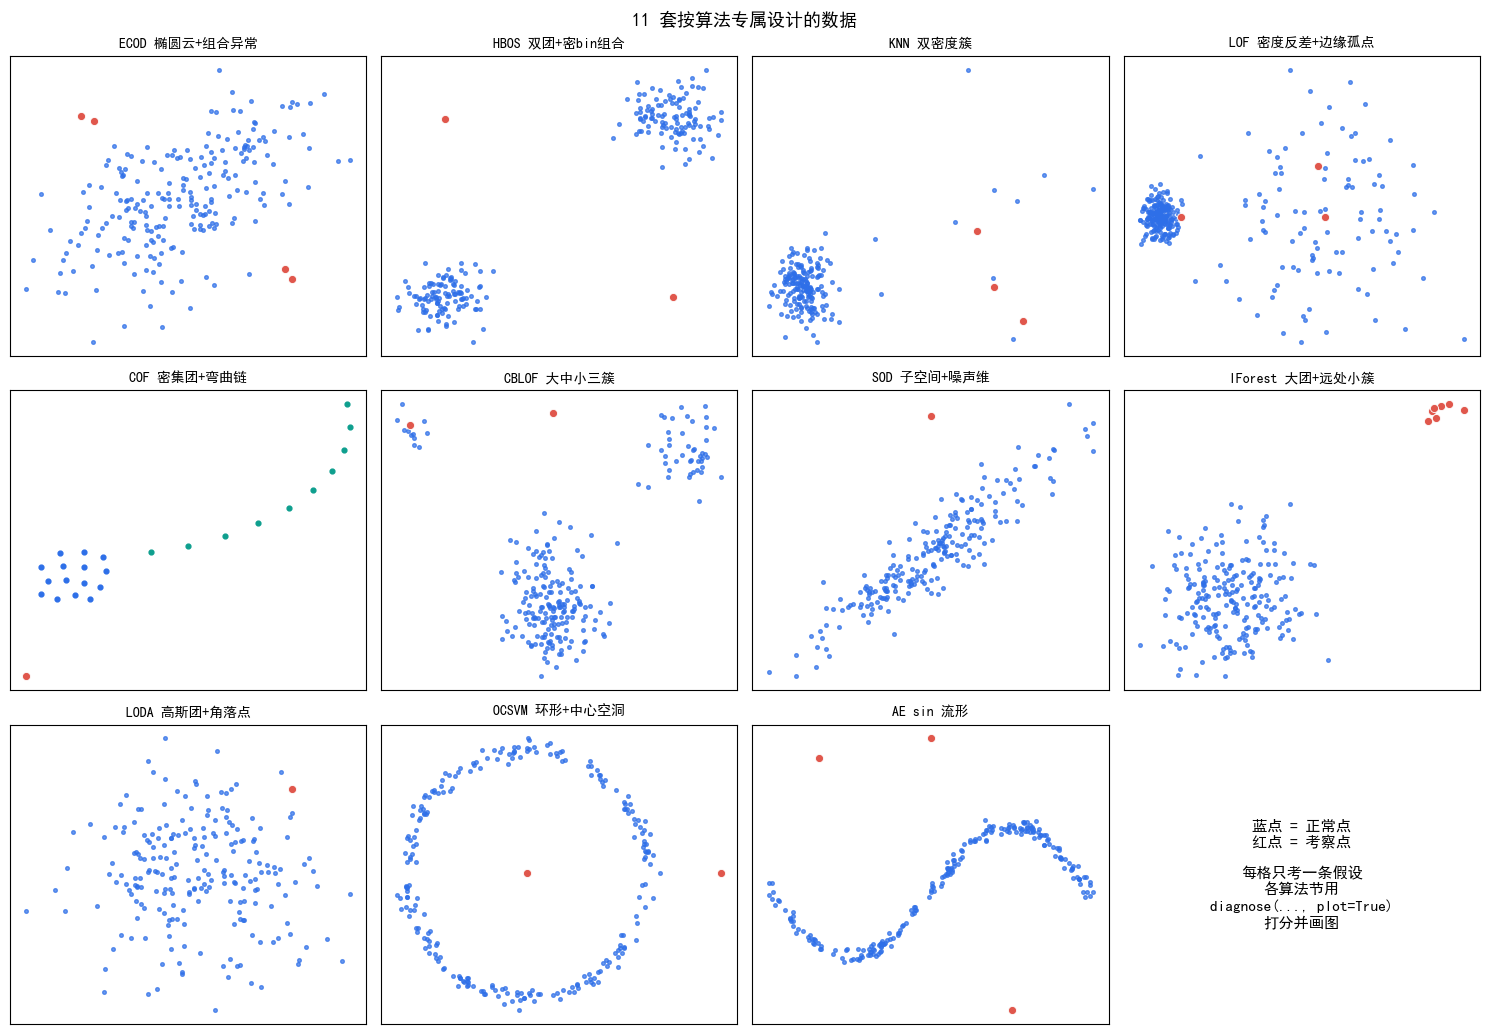

In [3]:
# --- 一次看完 11 套专属数据的形状 ---
preview_cases()                                                 # 调用预览函数，画 3×4 网格

> 📦 **公共基准数据**：单高斯一团 + 5% 均匀异常点，800 训练 / 200 测试。
> **不进正文主线**，仅供附录使用（附录 A 的分数融合要求多个基模型在同一份数据上打分）。

In [4]:
# --- 实验准备：公共基准数据（仅附录使用）---
from pyod.utils.data import generate_data                       # PyOD 自带数据生成器

X_train, X_test, y_train, y_test = generate_data(               # 生成训练 / 测试集
    n_train=800, n_test=200, n_features=2,                      # 800 / 200 个二维样本
    contamination=0.05, random_state=42)                        # 5% 异常率；固定种子

print(f"公共基准数据就绪: train={X_train.shape},"               # 训练集形状
      f" test={X_test.shape}（仅附录使用）")                    # 测试集形状

公共基准数据就绪: train=(800, 2), test=(200, 2)（仅附录使用）


## 第一族｜分布与概率密度：异常 = 小概率事件
> 🧭 **主线进度**：`Ⅰ ─→ Ⅱ ─→ Ⅲ ─→ Ⅳ` 当前 **第 Ⅰ 环（起点）**｜本族把 $\mathcal{M}_{normal}$ 定义成「**各维高概率区**」｜本族破口：看不见特征组合 → 交给 Ⅱ 族。

### 族导语：统一模型、共同假设、共同破口

**统一模型**：假设各特征相互独立，联合密度可用边际密度近似

$$
P(x) \approx \prod_{j=1}^{d} P_j(x_j)
\quad\Longrightarrow\quad
\boxed{\ \text{score}(x) = \sum_{j=1}^{d} -\log P_j(x_j)\ }
$$

取负对数是为了让「概率越小 → 分数越大」，符合 PyOD「分数越高越异常」的约定。**这一族唯一的建模工作，就是估计一维的 $P_j$**。

| 共同点 | 说明 |
| :--- | :--- |
| ✅ 共同优势 | 只需排序 / 分桶，$O(nd)$ 线性、无迭代、无需缩放、天然可解释（能指出「是哪个特征的哪个区间」导致异常） |
| ⚠️ 共同假设 | **特征独立**。相关性结构（如身高×体重、$x_1\approx x_2$ 的线性带）完全看不见 |
| 💥 共同破口 | 一个点在每一维都不极端，但落在「维度的组合」上很反常时，Ⅰ 族会漏检 |

**族内递进**：估计 $P_j$ 的方式由「无参数」到「离散化」

| 算法 | 怎么估 $P_j$ | 关键假设 | 参数敏感度 |
| :--- | :--- | :--- | :--- |
| **ECOD** | 经验累积分布（ECDF），直接看左右尾部概率 | 几乎无假设 | 低（无需调参，首选 Baseline） |
| **HBOS** | 直方图分桶，用桶高当概率 | 分桶粒度 + 独立性 | 中（`n_bins` 决定粒度） |

> 💡 教学提示：学完这两个算法后回看实验输出 —— Ⅰ 族是**逐维打分再相加**，所以「两维各自正常、组合反常」的点抓不到（专属数据考的正是这条盲区）。这就是「特征独立假设」的指纹；后面 Ⅱ 族将亲手修掉它。

---

### 1.1 ECOD (Empirical Cumulative Distribution-based Outlier Detection)
> 🧭 **主线定位**：正常 = 各维高概率区｜分数 = $-\log P(x)$｜本节破口：组合反常的点两维都不极端 → Ⅱ 族补

**🧠 核心原理深度解析**：

传统的 Z-Score 假设数据服从正态分布，这在现实世界中很少成立。**ECOD 的核心思想是“非参数尾部概率估计”**。

1. **单维投影**：它将多维数据分解为一个个独立的一维特征向量。
2. **经验累积分布 (ECDF)**：对于每个特征，它不拟合任何分布曲线，而是直接根据排序后的数据计算累积概率。如果某个值位于排序的最顶端或最底端，其尾部概率就很小。
3. **极端值检测**：ECOD 分别计算左侧尾部（极小值）和右侧尾部（极大值）的概率，取两者中的较大者作为该维度的异常得分。
4. **多维聚合**：将所有维度的得分相加（或取最大），得到最终的异常分数。

**💡 为什么它快且稳？**
- **无需迭代**：只需要对数据进行排序（O(n log n)），没有复杂的优化过程。
- **无分布假设**：无论是偏态、双峰还是长尾分布，只要偏离中心就是异常，它都能捕捉。
- **线性扩展**：复杂度仅为 O(n·d)，百万级数据秒出结果。

**⚙️ 关键参数**：
- `tail_level`: 控制关注哪一侧的尾部（left/right/both）。默认 both。
- `disposal_percentile`: 丢弃多少比例的极端值以防止离群点影响 ECDF 的计算（鲁棒性增强）。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/ECOD图解.html" target="_blank">👉 在浏览器打开 ECOD图解</a>](http://127.0.0.1:5500/html/ECOD图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：220 个正常点铺成一团 `y ≈ 0.5x` 的普通椭圆云（中等相关，相关系数约 0.6，画出来是一团有厚度的云，不是一条细线）；考察点为 4 个 `(1.6, −1.6)` 型组合异常点 —— x、y 单独看都还在正常点的分布范围内（约 P4~P97）。
> - **考什么**：ECOD 只算每一维的尾部概率再相加；这 4 个点每一维上只是「稍微靠边」（约 1.4~1.6σ），但按 `y ≈ 0.5x` 的组合关系衡量，它们斜着偏出云的主轴约 2.5~3σ —— 两个中等尾巴相加，仍低于云两端那些单维极端点的分数，正好卡在「逐维相加」的盲区。
> - **对答案**：对照本节实验输出：组合异常大多排不进 P95 —— 这就是 Ⅰ 族「特征独立假设」的代价。


[ECOD·专属] ECOD        | 正常点 P95=6.308 | 考察点=[5.813 5.619 4.98  5.024] | 高于 P95: 0%


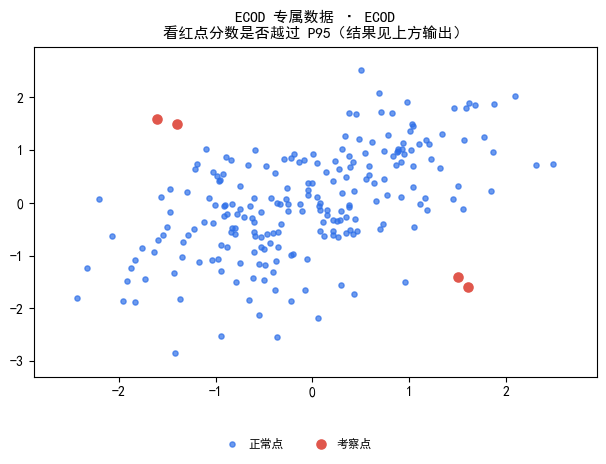

(array([4.12796117, 2.49195623, 2.52160493, 3.71060128, 1.73884559,
        3.36070602, 4.01876188, 4.58067917, 1.84846101, 5.05391382,
        3.22094408, 3.46276511, 4.1126937 , 2.16606231, 4.35110472,
        2.48523728, 6.06875622, 1.76565685, 3.63185879, 2.36239651,
        2.08674084, 6.77992191, 4.87375209, 1.60202742, 3.09834176,
        3.60186808, 2.18278389, 1.94957388, 4.75177366, 2.39562512,
        2.14325305, 2.16678355, 3.48610729, 4.78090193, 5.44971701,
        4.01303121, 1.5871671 , 3.25089115, 6.9805926 , 2.59274958,
        2.34586361, 3.13186445, 3.44253604, 2.77988802, 2.39336012,
        2.69165639, 5.59429824, 3.28066331, 1.60716776, 2.06451222,
        4.78336803, 3.26485486, 6.14286419, 4.09022085, 2.40932397,
        3.78055987, 2.8498804 , 5.93522483, 2.61198899, 2.3142228 ,
        2.08507723, 2.00385886, 1.48160454, 6.10512387, 2.69287665,
        5.29831737, 2.45398474, 2.96962965, 2.50629069, 2.61961938,
        2.4127782 , 1.92618855, 6.83601137, 2.17

In [5]:
# --- ECOD · 专属数据实验（椭圆云上的组合异常）---
from pyod.models.ecod import ECOD                               # Ⅰ 族：经验累积分布

m = ECOD(contamination=0.05)                                    # 5% 阈值
diagnose(m, 'ECOD', 'ECOD', plot=True)                          # 训练 + 打分 + 画图

### 1.2 HBOS (Histogram-based Outlier Score)
> 🧭 **主线定位**：正常 = 各维高概率区（分桶版）｜分数 = $-\log P(x)$｜本节破口：最密 bin 的组合也可能从未出现 → Ⅱ 族补

**🧠 核心原理深度解析**：

HBOS 基于一个强假设：**特征之间相互独立**。在此假设下，联合概率密度等于各边缘概率密度的乘积。

1. **直方图构建**：对每个特征单独构建直方图。横轴是特征取值范围，纵轴是该区间内的样本数量（频率）。
2. **概率估计**：样本落在某个 Bin（桶）里的概率 $P(bin)$ 近似为该 Bin 的高度除以总样本数。
3. **异常分数定义**：异常意味着“罕见”。因此，异常分数定义为负对数似然：
   $$ Score(x) = \sum_{j=1}^{d} -\log(P_j(x_j)) $$
   *(注：取负对数是因为概率越小（越罕见），-log(P) 越大，符合“分数越高越异常”约定。)*
4. **平滑处理**：为了防止某些 Bin 为空导致概率为 0（-log(0) 无穷大），引入拉普拉斯平滑项 `alpha`。

**💡 优势与局限**：
- **优势**：天然的可解释性。你可以清楚地看到是哪个特征的哪个区间导致了高分。速度极快。
- **局限**：当特征间存在强相关性时（如身高和体重），独立性假设失效，可能导致误判。

**⚙️ 关键参数**：
- `n_bins`: 直方图的桶数。太少则粒度粗，太多则稀疏Bin增多导致噪声大。建议 10-50。
- `alpha`: 平滑系数。默认 0.1。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/HBOS图解.html" target="_blank">👉 在浏览器打开 HBOS图解</a>](http://127.0.0.1:5500/html/HBOS图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：两个团分别在 `(−1.8, −1.8)` 与 `(1.8, 1.8)`；考察点为 `(−1.8, 1.8)`、`(1.8, −1.8)` 两个组合从未出现过的点。
> - **考什么**：两点的 x、y 各自都落在直方图最密的 bin 里，等宽分箱下乘积概率很高 —— 专门考「轴平行直方图」。
> - **对答案**：对照本节实验输出：只调分箱数很难救回来，需要换一族模型。


[HBOS·专属] HBOS        | 正常点 P95=3.792 | 考察点=[1.31  1.504] | 高于 P95: 0%


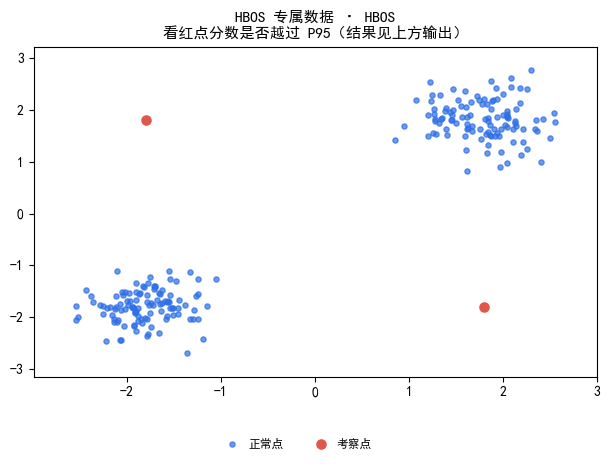

[HBOS·专属] HBOS(n_bins=50) | 正常点 P95=3.622 | 考察点=[0.778 0.802] | 高于 P95: 0%


(array([1.9523453 , 1.67682296, 0.7673517 , 2.08947285, 2.13895805,
        0.94340169, 2.17417839, 1.32102719, 1.37697172, 0.94340169,
        2.46807132, 1.1244346 , 0.91551529, 1.91342287, 1.9523453 ,
        1.34272529, 0.7673517 , 2.31433511, 1.34272529, 1.76849235,
        1.74823719, 2.56616805, 2.56596303, 2.96316666, 0.6972246 ,
        0.7673517 , 1.1244346 , 3.3549513 , 3.30811751, 1.30048458,
        0.91551529, 1.51877527, 1.9523453 , 1.91342287, 2.45357838,
        1.76849235, 2.3578572 , 1.81709549, 2.62110017, 2.78425372,
        3.17578806, 1.88712511, 1.32102719, 0.91551529, 0.59933289,
        1.20259287, 2.17417839, 1.91342287, 3.02895197, 0.7673517 ,
        1.51877527, 2.37640192, 2.37640192, 1.91342287, 4.66642798,
        1.02654289, 2.20888013, 0.59933289, 2.44424535, 0.94340169,
        1.76849235, 0.5076635 , 0.6972246 , 1.9523453 , 4.31298378,
        2.81066128, 2.56616805, 0.59933289, 2.37640192, 0.93487349,
        2.20888013, 1.74823719, 1.91342287, 1.34

In [6]:
# --- HBOS · 专属数据实验（默认分箱 vs 细分箱）---
from pyod.models.hbos import HBOS                               # Ⅰ 族：直方图密度

m = HBOS(n_bins=15)                                             # 默认 15 个分箱
diagnose(m, 'HBOS', 'HBOS', plot=True)                          # 训练 + 打分 + 画图
diagnose(HBOS(n_bins=50), 'HBOS', 'HBOS(n_bins=50)')            # 细分箱也救不了

### Ⅰ 族小结

| | ECOD | HBOS |
| :--- | :--- | :--- |
| 密度估计 | 经验累积分布（无参数） | 直方图（需分桶） |
| 需调参 | 几乎不用 | `n_bins`（10–50）、`alpha` 平滑 |
| 对偏态 / 长尾 | 稳 | 取决于分桶 |
| 可解释性 | 能定位到特征与左 / 右尾 | 能定位到具体 bin |
| 何时选 | **第一跑的 Baseline**、百万级数据 | 指标监控、需要根因归因 |

**族的共同边界**：只要业务里的异常体现在「多个特征的组合关系」上（例如「交易额正常、频次正常，但两者不匹配」），就该往 Ⅱ 族或 Ⅳ 族走。

---

> 🔗 **回到主线**：本族共同破口是「看不见特征之间的组合关系」→ 这正是 **Ⅱ 族**用样本间几何关系要补的。


## 第二族｜邻近度与局部几何：异常 = 孤立或稀疏
> 🧭 **主线进度**：`Ⅰ ─→ Ⅱ ─→ Ⅲ ─→ Ⅳ` 当前 **第 Ⅱ 环**｜本族把 $\mathcal{M}_{normal}$ 定义成「**邻居密集、密度与周围一致**」｜补上 Ⅰ 族的组合关系盲区；本族破口：$O(n^2)$ 与高维失效 → 交给 Ⅲ 族。

### 族导语：把「正常」从「分布」换成「邻居」

Ⅰ 族问的是「这个取值常不常见」；Ⅱ 族问的是「**这个点周围有没有人**」。它彻底放弃分布假设，只依赖一个距离度量 $d(\cdot,\cdot)$：

$$
\text{score}(x) = f\Big(\ \{\ d(x, x_i)\ \mid\ x_i \in \mathcal{N}_k(x)\ \}\ \Big)
$$

> ⚠️ **全族前置动作：必须特征缩放**。距离对量纲敏感，量纲大的特征会单方面主导近邻。本章统一用 `RobustScaler`（基于中位数与 IQR，抗离群点，比 `StandardScaler` 更适合异常检测）。

**族内递进（一条清晰的「破口链」）**：

| 顺序 | 算法 | 用什么当分数 | 补上了上一节的什么破口 | 代价 |
| :--- | :--- | :--- | :--- | :--- |
| 2.1 | **KNN** | 第 $k$ 近邻距离 | 从「分布」改成「几何」，不假设分布 | 隐含 **全局密度均匀** 假设 |
| 2.2 | **LOF** | 自己密度 / 邻居密度 之比 | 修掉全局均匀假设 → 适应多密度簇 | 仍是欧氏距离，$O(n^2)$ |
| 2.3 | **COF** | 链式（最短路径）距离下的密度比 | 修掉「簇必须是球状」→ 适应弯曲流形 | 更慢，大样本需降采样 |
| 2.4 | **CBLOF** | 到（大）簇心的距离 × 簇大小 | 把「局部邻居」换成「全局簇结构」→ $O(nk)$ 更快 | 依赖聚类结果 |
| 2.5 | **SOD** | 在方差最小的子空间里算 LOF | 修掉高维下「所有点一样远」→ 维度去噪 | 计算量大，中小规模 |

> 📌 一句话记住全族：**KNN 看绝对距离，LOF 看相对密度，COF 看形状，CBLOF 看簇，SOD 看维度**。五个算法共用同一个「近邻」内核，只是把比较的参照系换了五次。

---

### 2.1 KNN (K-Nearest Neighbors)
> 🧭 **主线定位**：正常 = 第 k 个邻居也不远｜分数 = $d_k(x)$｜本节破口：隐含「全局密度均匀」→ 2.2 LOF 补

**🧠 核心原理深度解析**：

KNN 是最直观的“局部异常”探测器。它的逻辑非常简单：**如果你周围很空旷，那你就是异常。**

1. **近邻搜索**：对于查询点 $x$，找到训练集中距离它最近的 $k$ 个点。
2. **距离聚合**：计算 $x$ 到这 $k$ 个邻居的距离，并根据 `method` 参数进行聚合：
   - `'largest'`: 取第 $k$ 个最近邻的距离（即最远的那个邻居）。这是最常用的，因为它对局部噪声不那么敏感。
   - `'mean'`: 取 $k$ 个邻居距离的平均值。
   - `'median'`: 取中位数。
3. **异常分数**：聚合后的距离即为异常分数。距离越大，说明该点越孤立。

**💡 致命弱点**：
- **全局均匀性假设**：KNN 隐含假设整个数据空间的密度是大致均匀的。如果数据中有两个簇，一个很紧密，一个很稀疏，KNN 会把稀疏簇中的所有点都标记为异常，即使它们是正常的。
- **维度灾难**：在高维空间中，所有点之间的距离趋于相等，KNN 失效。

**⚙️ 关键参数**：
- `n_neighbors`: $k$ 值。太小容易受噪声干扰，太大可能跨越簇边界。建议 5-20。
- `algorithm`: `'ball_tree'` (推荐，适合中高维), `'kd_tree'` (低维最快), `'brute'` (暴力法，万能但慢)。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.KNN.原理图解.html" target="_blank">👉 在浏览器打开 KNN原理图解</a>](http://127.0.0.1:5500/html/PyOD.KNN.原理图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：左簇 180 点紧密（σ=0.35）、右簇 10 点稀疏（σ=1.5，占比 < 5%），**两簇全是正常点**；3 个考察点也取自稀疏簇内部。
> - **考什么**：KNN 的分数就是第 k 近邻的绝对距离；密度差一个数量级时，这个量在两个簇之间根本不可比。
> - **对答案**：对照本节实验输出：这几个「正常点」大多高于 P95 —— 这里的高分恰恰说明**误报**，不是检出成功。


[KNN·专属] KNN         | 正常点 P95=1.178 | 考察点=[3.666 3.463 4.345] | 高于 P95: 100%


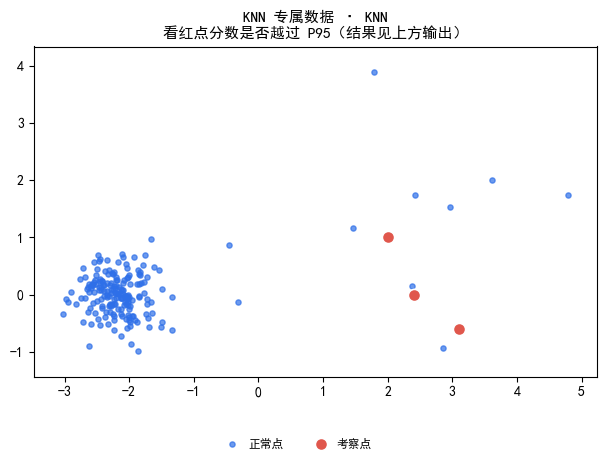

(array([0.13669496, 0.3513674 , 0.21369871, 0.37360578, 0.32105539,
        0.14601522, 0.15135498, 0.24786773, 0.52900041, 0.28069786,
        0.18144127, 0.19371889, 0.72634787, 0.42946429, 0.1787274 ,
        0.25428733, 0.27866579, 0.40017202, 0.16538592, 0.33693945,
        0.21427848, 0.16137102, 0.28774904, 0.26544322, 0.29077276,
        0.17094521, 0.15044595, 0.23523417, 0.28020089, 0.23084758,
        0.26700924, 0.22340094, 0.94846329, 0.30444612, 0.15263788,
        0.11086852, 0.48638558, 0.18682487, 0.34977505, 0.1683069 ,
        0.12820435, 0.45275443, 0.44797631, 0.44666614, 0.14016557,
        0.34011767, 0.26234416, 0.17642827, 0.34913558, 0.10959008,
        0.22945751, 0.40399781, 0.20009526, 0.25954592, 0.16113883,
        0.86365063, 0.18803134, 0.26333181, 0.13629446, 0.15461547,
        0.14223881, 0.31198928, 0.18401006, 0.11249319, 0.1927422 ,
        0.34366776, 0.14667439, 0.38919052, 0.15012716, 0.1288831 ,
        0.47475601, 0.27124399, 0.18126687, 0.11

In [7]:
# --- KNN · 专属数据实验（双密度簇）---
from pyod.models.knn import KNN                                 # Ⅱ 族：k 近邻距离

m = KNN(n_neighbors=10)                                         # 10 近邻
diagnose(m, 'KNN', 'KNN', scale=True, plot=True)                # 标准化 + 打分 + 画图

### 2.2 LOF：把「绝对距离」改成「相对密度」
> 🧭 **主线定位**：正常 = 密度与邻居相当｜分数 = 局部密度比｜本节破口：邻域仍是球状 → 2.3 COF 补

**破口**：KNN 说「你离邻居远 → 你异常」。但在稀疏簇里，*所有*正常点都离邻居远。LOF 换了个参照系 —— **不看你离邻居多远，看你的密度和邻居的密度差多少**。

1. **k-距离** $d_k(x)$：$x$ 到第 $k$ 个近邻的距离。
2. **可达距离** $\text{reach}_k(x \leftarrow o) = \max\{d_k(o),\ d(x,o)\}$：用 $o$ 的邻域尺度做平滑，抑制 $x$ 附近的距离抖动。
3. **局部可达密度** $\text{lrd}_k(x) = 1 \big/ \big( \frac{1}{k}\sum_{o \in \mathcal{N}_k(x)} \text{reach}_k(x \leftarrow o) \big)$。
4. **LOF 分数**：

$$
\text{LOF}_k(x) = \frac{\frac{1}{k}\sum_{o \in \mathcal{N}_k(x)} \text{lrd}_k(o)}{\text{lrd}_k(x)}
$$

| LOF 值 | 含义 |
| :--- | :--- |
| $\approx 1$ | 我和邻居一样密 → **正常**（哪怕这个簇整体很稀疏） |
| $\gg 1$ | 我明显比邻居稀疏 → **异常** |

> 💡 这就是「局部」二字的分量：分数是 **相对量**，因此能同时容纳紧密簇与稀疏簇 —— KNN 误报的稀疏簇普通点，这里分数回落到 P95 附近；真正孤立的点则仍然显著偏高。

**⚙️ 关键参数**：`n_neighbors`（建议 20+，要大于单个簇内可能的近邻数；太小易被噪声扰动，太大会跨越簇边界）。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.LOF.原理图解.html" target="_blank">👉 在浏览器打开 LOF原理图解</a>](http://127.0.0.1:5500/html/PyOD.LOF.原理图解.html)
> 🎯 **本节实验 · 专属数据**
> - **题目**：更极端的密度反差（左 200 点 σ=0.28、右 100 点 σ=1.6）；考察点为 2 个稀疏簇普通点 + 1 个紧贴密簇边缘的孤点。
> - **考什么**：LOF 比的是「我的密度 vs 邻居的密度」，只有同时存在「整体稀疏但局部一致」和「局部明显更稀」两类点，才看得出相对量的价值。
> - **对答案**：对照本节实验输出：前 2 点分数回落到 P95 附近，第 3 点明显高于 P95。


[LOF·专属] LOF         | 正常点 P95=1.435 | 考察点=[0.972 0.979 1.459] | 高于 P95: 33%


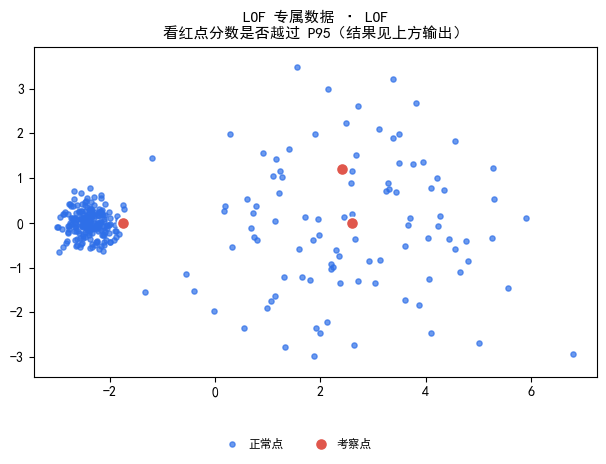

(array([1.02381236, 0.97654844, 1.11596657, 1.02370215, 0.9582335 ,
        1.01498085, 0.99741226, 1.00396338, 1.05444611, 1.00793326,
        1.02231147, 1.01029828, 1.02688166, 1.23415562, 0.98590808,
        1.268794  , 1.48802713, 0.96654436, 0.99397477, 0.99777856,
        0.95885472, 1.24446249, 1.04243631, 1.28076424, 1.43056074,
        1.10147361, 0.95645061, 0.94545553, 1.06356385, 1.01828144,
        1.08483745, 0.99313246, 0.95280854, 1.18628645, 1.0844833 ,
        1.02924096, 1.26568399, 1.13183551, 0.99387361, 1.05841886,
        1.13831242, 1.05807348, 1.13302775, 1.11916925, 1.01847875,
        1.29936085, 1.4327256 , 1.01224893, 0.98782437, 1.00267135,
        0.98826169, 0.99564288, 1.0304498 , 0.96640155, 0.98204514,
        1.04307949, 1.16021793, 1.41591379, 0.97309335, 0.98429736,
        1.07860984, 0.98363059, 1.0031355 , 1.91478294, 1.08437103,
        1.05379447, 0.97309335, 1.13438697, 0.96654436, 1.00516904,
        1.08419175, 1.34086603, 1.069149  , 0.99

In [8]:
# --- LOF · 专属数据实验（极端密度反差）---
from pyod.models.lof import LOF                                 # Ⅱ 族：局部离群因子

m = LOF(n_neighbors=20)                                         # 20 近邻，看相对密度
diagnose(m, 'LOF', 'LOF', scale=True, plot=True)                # 标准化 + 打分

### 2.3 COF：当「簇」不是球，而是一条弯曲的带子
> 🧭 **主线定位**：正常 = 沿链式方向可达｜分数 = 链式密度比｜本节破口：仍是 $O(n^2)$ → 2.4 CBLOF 提速

**破口**：LOF 仍用欧氏距离定义邻域，隐含「正常区域是各向同性的团」。若正常数据呈**流形 / 链状**（如轨迹、工艺曲线、螺旋），沿带子方向走很远其实仍是正常，LOF 会把它当成低密度。

1. 先用欧氏距离找 $k$ 近邻，建立邻接图。
2. 在图上计算 **链式距离 / 最短路径距离**（SBN-path：从 $x$ 出发每次选最近的未访问点，累加边长），得到「沿数据流形走」的距离。
3. 用链式距离算可达密度与密度比，思路与 LOF 相同。

$$
\text{COF}(x) \propto \frac{\text{avg chaining density of } \mathcal{N}(x)}{\text{chaining density of } x}
$$

> 💡 **一句话差别**：LOF 用「直线距离」量密度，COF 用「顺着数据形状走的距离」量密度。因此 COF 在流形数据上优于 LOF，代价是更重 —— 它要对每个点维护最短路径，是本章最慢的算法。

**⚠️ 两个工程坑**：

1. COF 是 $O(n^2)$ 算法，上万样本请先降采样，或改用 CBLOF（同为聚类视角、复杂度更低）。
2. PyOD 的 COF `decision_function` 是**对传入集合内部**算分（近邻在集合里找），不是对照训练集打分；集合点数 ≤ `n_neighbors` 时直接 `IndexError`。因此本节对照实验取**整批训练分数** `decision_scores_`，`diagnose` 用 `joint=True` 把孤点并入整批再拆开。SOD 的实现同理（见 2.5 节）。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.COF.原理图解.html" target="_blank">👉 在浏览器打开 COF原理图解</a>](http://127.0.0.1:5500/html/PyOD.COF.原理图解.html)
> 🎯 **本节实验 · 专属数据**
> - **题目**：15 点密集团 + 10 点间距逐渐拉大的弯曲链 + 1 个远处孤点（26 个手工点取自链式流形经典例题）。
> - **考什么**：链上点沿一个方向连续排列、局部密度低但方向一致 —— 这正是「链式距离」与「各向同性邻域」分道扬镳之处。
> - **对答案**：对照本节实验输出：LOF 的链 / 团分差明显更大，COF 更接近。


LOF | 密集团均分 1.018 | 链中段均分 1.047
COF | 密集团均分 0.998 | 链中段均分 0.998
[COF·专属] COF         | 正常点 P95=1.206 | 考察点=[2.98] | 高于 P95: 100%


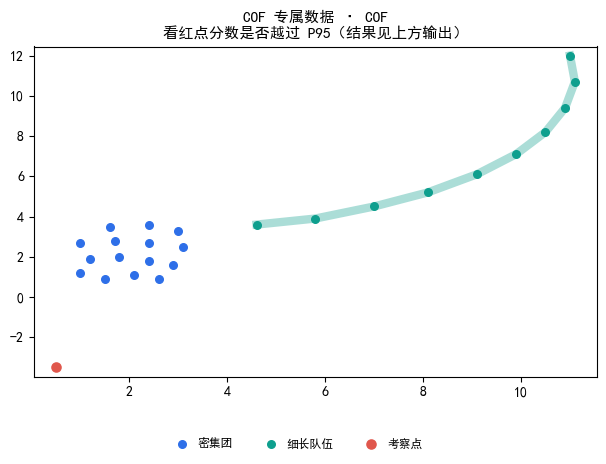

(array([0.97659562, 0.95388487, 0.94448085, 0.94877036, 1.02540965,
        0.99079113, 0.98542767, 1.02432458, 1.01918693, 0.99974024,
        1.02695876, 1.06703823, 0.99981549, 1.0234421 , 0.98187872,
        1.33914063, 1.24054359, 1.02997195, 1.01648857, 1.0032228 ,
        0.99122353, 0.98906153, 0.99726597, 1.00528119, 1.00528119]),
 array([2.98036232]))

In [9]:
# --- COF · 专属数据实验（与 LOF 同场对照）---
from pyod.models.cof import COF                                 # Ⅱ 族：链式连通离群因子
from pyod.models.lof import LOF                                 # 对照组：LOF

X_cof = CASES['COF']['X']                                       # 15 点密集团 + 10 点弯曲链

pairs = [('LOF', LOF(n_neighbors=5)),                           # LOF：对照组
         ('COF', COF(n_neighbors=5))]                           # COF：主角
for nm, m in pairs:                                             # 同一批点上逐个训练
    m.fit(X_cof)                                                # 在 25 个点上训练
    s = np.asarray(m.decision_scores_)                          # 取训练集自身的分数
    print(f"{nm} | 密集团均分 {s[:15].mean():.3f}"              # 团的均分
          f" | 链中段均分 {s[20:25].mean():.3f}")               # 链中段的均分

m = COF(n_neighbors=5)                                          # 5 近邻
diagnose(m, 'COF', 'COF', plot=True, joint=True)                # 并入整批 + 画图

### 2.4 CBLOF：聚类视角的「全局距离」(Cluster-Based Local Outlier Factor)
> 🧭 **主线定位**：正常 = 属于某个（大）簇｜分数 = 到簇心距离 × 簇大小｜本节破口：高维下簇结构退化 → 2.5 SOD 补

> 📌 **归族说明**：CBLOF 的分数本质仍是「到某个中心的距离」，属于 Ⅱ 族；它只是用 KMeans 先把「邻居」换成了「簇」，从而把复杂度从 $O(n^2)$ 降到 $O(nk)$。它不是独立的一族，也不是聚类算法本身。

**🧠 核心原理深度解析**：

CBLOF 用一次 KMeans 把「逐点近邻」换成「簇」，从而把打分从 LOF 式的局部密度比简化为到簇心的加权距离，目标是在大规模数据上提速并容忍簇大小不均。

1. **聚类预处理**：首先使用 KMeans 或其他聚类算法将数据划分为若干簇。
2. **簇分类**：根据簇的大小，将其分为“大簇”（Large Clusters）和“小簇”（Small Clusters）。
   - 大簇代表主要的正常模式。
   - 小簇可能代表微小的正常群体，也可能全是异常。
3. **距离计算**：
   - 对于属于 **大簇** 的点：计算其到所属簇中心的距离。
   - 对于属于 **小簇** 的点：计算其到 **最近的大簇中心** 的距离。
4. **加权异常分数**：
   $$ Score(x) = size(cluster) \times distance(x, center) $$
   - **直觉**：如果一个点离一个大簇的中心很远，那它很可能是异常（因为大簇覆盖了大部分正常数据）。如果一个点在一个小簇里，它离最近大簇越远，异常可能性越大。

**💡 优势**：
- 比 LOF 快，因为不需要计算所有点对的距离，只需计算点到簇心的距离。
- 能更好地处理簇密度差异极大的情况。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.CBLOF.原理图解.html" target="_blank">👉 在浏览器打开 CBLOF原理图解</a>](http://127.0.0.1:5500/html/PyOD.CBLOF.原理图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：大簇 180 点 + 中簇 45 点 + 远处小簇 12 点，规模差一个量级；考察点取小簇中心与簇间空地各 1 点。
> - **考什么**：CBLOF 先按规模把簇分成「大 / 小」，小簇的点一律按「到最近大簇中心的距离」打分 —— 数据里真有大小簇，这条规则才看得见。
> - **对答案**：对照本节实验输出：小簇相关点分数高；调 `alpha` 会改变谁被划进小簇。


[CBLOF·专属] CBLOF       | 正常点 P95=1.394 | 考察点=[2.821 2.032] | 高于 P95: 100%


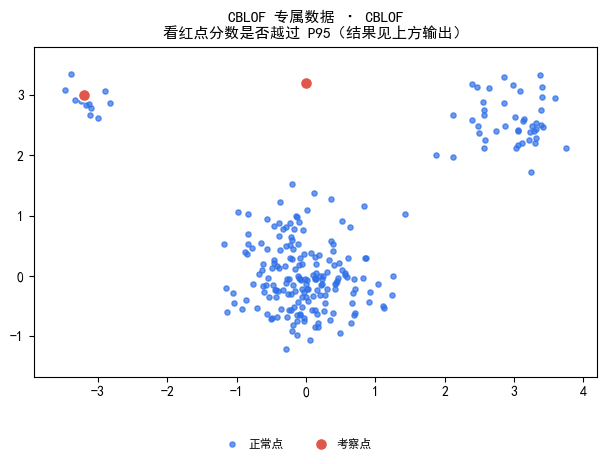

[CBLOF·专属] CBLOF(alpha=0.60) | 正常点 P95=2.839 | 考察点=[2.821 2.122] | 高于 P95: 0%


(array([0.14166167, 0.30545925, 0.46085644, 0.30322588, 0.31796003,
        0.59619345, 0.31805921, 0.22654838, 0.18295702, 0.27773404,
        0.47360494, 0.06820923, 1.11121367, 0.54035461, 0.23425852,
        0.58900491, 0.47022622, 0.29964318, 0.43109216, 0.44754981,
        0.68412087, 0.8077118 , 0.11408799, 0.58720875, 0.67310078,
        0.35988263, 0.12045476, 0.40521379, 0.468962  , 0.38260473,
        0.33308106, 0.21055502, 0.35644183, 0.0794646 , 0.30584005,
        0.50058373, 0.22351042, 0.17660106, 0.67638011, 0.54439404,
        0.31314269, 0.33635267, 0.49140513, 0.49682204, 0.79756359,
        0.56505617, 0.71325418, 0.52334689, 0.32701964, 0.33942083,
        0.25509807, 0.51444621, 0.37090848, 0.35882186, 0.43050939,
        0.3496916 , 0.37931763, 0.17724588, 0.20948508, 0.1936089 ,
        0.38178582, 0.27622437, 0.49452927, 0.55210767, 0.55670947,
        0.27580393, 0.31251759, 0.48371503, 0.46321997, 0.73275888,
        0.27331485, 0.55859291, 0.30290553, 0.30

In [10]:
# --- CBLOF · 专属数据实验（alpha 决定谁是小簇）---
from pyod.models.cblof import CBLOF                             # Ⅱ 族：基于聚类的离群因子

m = CBLOF(n_clusters=4, alpha=0.85,                             # 4 簇；alpha=0.85 定大簇
          random_state=42)                                      # 固定种子可复现
diagnose(m, 'CBLOF', 'CBLOF', scale=True, plot=True)            # 标准化 + 画图
m = CBLOF(n_clusters=4, alpha=0.60,                             # alpha 降到 0.60 做对比
          random_state=42)                                      # 同上
diagnose(m, 'CBLOF', 'CBLOF(alpha=0.60)', scale=True)           # 只看分数

### 2.5 SOD：子空间视角的 LOF 变体 (Subspace Outlier Detection)
> 🧭 **主线定位**：正常 = 低方差子空间里不偏离｜分数 = 子空间 LOF｜**全族总破口**：$O(n^2)$ + 高维 → Ⅲ 族范式反转

> 📌 **归族说明**：SOD 的内核就是 LOF，只是把「在哪个空间里找邻居」从全维度换成了低方差子空间，因此归 Ⅱ 族而非另立「子空间类」。它是 Ⅱ 族应对维度灾难的答案。

**🧠 核心原理深度解析**：

SOD 专为 **高维数据** 设计。在高维空间中，全局距离失效，但异常往往只在 **特定的低维子空间** 中显现（例如：一个人在“收入”和“年龄”维度正常，但在“消费额”和“职业”构成的子空间中异常）。

1. **参考集构建**：对于每个点 $x$，找到其 $k$ 个最近邻，构成参考集 $Ref(x)$。
2. **子空间发现**：在参考集中，找出那些在该子空间内方差较小（即点很聚集）的特征组合。
3. **子空间内 LOF**：仅在发现的这些“紧密子空间”内计算 LOF。
4. **聚合**：取所有子空间中 LOF 的最大值作为最终分数。

**💡 核心价值**：
- 忽略了无关噪声维度，专注于能揭示异常的维度组合。
- 计算量大，仅适用于中小规模高维数据。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.SOD.原理图解.html" target="_blank">👉 在浏览器打开 SOD原理图解</a>](http://127.0.0.1:5500/html/PyOD.SOD.原理图解.html)
**💻 代码实战**

**⚠️ 工程坑（与 COF 同源）**：PyOD 的 SOD `decision_function` 同样是**对传入集合内部**找近邻算分，不能只给一两个点打分 —— 本节 `diagnose` 用 `joint=True` 把子空间异常点并入 220 个正常点整批打分。

> 🎯 **本节实验 · 专属数据**
> - **题目**：前两维是 `y ≈ x` 的强相关带（相关系数约 0.92，画出来是一条有厚度的带，不是一条线），另加 8 维方差更大的噪声；考察点在相关子空间里偏离到 `(0, 3.5)`，噪声维取典型值（若全取 0，它的近邻全是噪声最小的点，子空间判断反而失真 —— SOD 的一个坑）。
> - **考什么**：全局欧氏距离被 8 个噪声维淹没，只有先找出相关子空间、在子空间里比密度才看得见。
> - **对答案**：对照本节实验输出：子空间异常点应高于 P95（图只画前两维，模型用完整 10 维打分）。


[SOD·专属] SOD         | 正常点 P95=1.726 | 考察点=[1.979] | 高于 P95: 100%


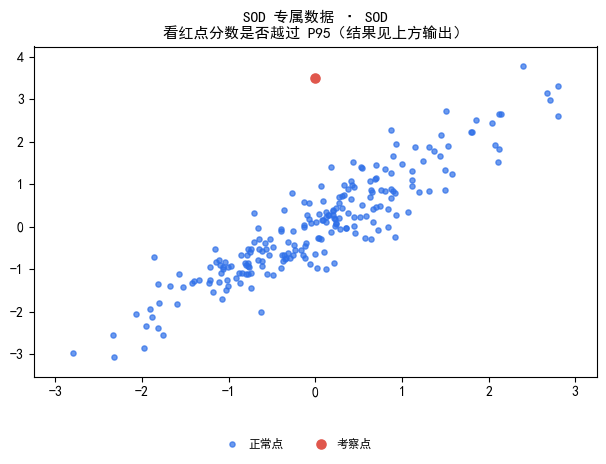

(array([1.47092164, 0.78982107, 0.43288066, 1.72492458, 0.37785807,
        0.530542  , 1.97612902, 0.79716759, 1.32394752, 1.54895132,
        1.69481775, 1.02558127, 0.49460148, 0.88658802, 0.41448946,
        0.81397132, 0.62185514, 0.84390143, 0.56727336, 0.50523465,
        1.10816734, 1.1725787 , 1.05813586, 0.49942028, 0.77693861,
        0.56831938, 1.28005259, 0.62305592, 1.15303348, 1.74520762,
        0.8004136 , 0.71559571, 0.2177886 , 0.74775786, 0.56107469,
        0.5097918 , 0.47099671, 2.22430181, 0.727189  , 1.19129867,
        1.60611167, 1.21790156, 1.0405537 , 0.72405964, 1.37794822,
        0.69237821, 1.13978891, 0.73920014, 1.62172557, 0.62645423,
        0.97878268, 0.78427316, 0.64536093, 1.43717617, 1.09026423,
        0.37590704, 0.74070719, 0.74079715, 0.50502477, 0.48061262,
        0.71943095, 1.52135743, 0.78182297, 0.64501519, 1.80084842,
        1.65349246, 0.74240997, 0.7619316 , 0.48076321, 0.72016455,
        1.07650317, 0.56850505, 0.67702922, 0.82

In [11]:
# --- SOD · 专属数据实验（10 维数据，图只画前两维）---
from pyod.models.sod import SOD                                 # Ⅱ 族：子空间离群检测

m = SOD(n_neighbors=20)                                         # 20 近邻
diagnose(m, 'SOD', 'SOD', plot=True, joint=True)                # 并入整批 + 画图

### Ⅱ 族小结：同一内核，五次换参照系

| 算法 | 参照系 | 打分 | 复杂度 | 最怕什么 |
| :--- | :--- | :--- | :--- | :--- |
| KNN | 全局绝对距离 | $d_k(x)$ | $O(n^2d)$ | 多密度簇、高维 |
| LOF | 邻居密度 | 密度比 | $O(n^2d)$ | 球状假设 / 高维 |
| COF | 流形上的链式距离 | 链式密度比 | $O(n^2d)$ 更重 | 大规模数据 |
| CBLOF | 簇心 | 距离 × 簇大小 | $O(nk)$ | 聚类数设错 |
| SOD | 低方差子空间 | 子空间 LOF | $O(n^2d)$ | 大规模数据 |

**全族共同的两道坎**：

1. **必须缩放**（距离度量）—— 忘了这步，结论全错。
2. **维度灾难**（$d>20$ 时近邻距离趋于相等）—— 此时应跳到 Ⅲ 族（IForest）或 Ⅳ 族（AE），或先用 PCA 降维。

> 🔗 与 Ⅰ 族的对照：Ⅰ 族逐维独立打分，看不见「组合反常」（专属数据里两维都不极端的点被漏掉）；Ⅱ 族按几何关系打分，这类点立刻现形。这就是「独立假设 vs 几何关系」最直观的证据。

---

> 🔗 **回到主线**：本族共同破口是「$O(n^2)$ + 高维失效」→ **Ⅲ 族**索性不再刻画正常，改为直接隔离异常。


## 第三族｜随机隔离与集成：异常 = 容易被孤立
> 🧭 **主线进度**：`Ⅰ ─→ Ⅱ ─→ Ⅲ ─→ Ⅳ` 当前 **第 Ⅲ 环（范式反转）**｜本族**不定义** $\mathcal{M}_{normal}$，直接利用「异常稀少且不同」去隔离｜补上 Ⅱ 族的 $O(n^2)$ / 高维短板；本族破口：偏离度量靠手工 → 交给 Ⅳ 族。

### 族导语：一次范式反转

前两族都在「先刻画正常，再算偏离」。Ⅲ 族反过来问：既然异常点 **稀少且与正常点不同**，那随机切几刀，谁先被单独切出来，谁就是异常。

$$
\text{score}(x) \propto \frac{1}{\text{平均「隔离」}x\text{ 所需的随机操作数}}
$$

| 反转带来的好处 | 原因 |
| :--- | :--- |
| 线性复杂度、能上百万级 | 不算两两距离，只做随机划分 / 随机投影 |
| 抗维度灾难 | 每次只随机用少数特征，避开高维距离退化 |
| 无需特征缩放 | 树的分割是阈值比较，对单调变换不变 |
| 天然适合集成 | 单次划分方差大，多棵树 / 多组投影取平均即可稳定 |

> ⚠️ **共同代价**：结果带随机性（务必设 `random_state`）、可解释性弱、对**局部异常**（藏在密集簇边缘的点）不如 Ⅱ 族敏感。

**族内递进**：

| 算法 | 随机化的对象 | 弱检测器 | 集成方式 | 与前族的关系 |
| :--- | :--- | :--- | :--- | :--- |
| **IForest** | 随机特征 + 随机切分点 | iTree 的路径长度 | $t$ 棵树平均 | 全新范式 |
| **LODA** | 随机投影方向 $w$ | 投影后一维直方图似然 | $M$ 个投影平均 | **桥梁**：用 Ⅰ 族的直方图当弱检测器，用 Ⅲ 族的随机集成把它们组合起来 |

> 💡 LODA 常被误当成树模型，它其实一棵树都没有：本质是 **「直方图的随机投影集成」**。把它放在本族末尾，正好回扣 Ⅰ 族、说明两族并不割裂。

---

### 3.1 Isolation Forest (iForest)
> 🧭 **主线定位**：正常 = *不定义*｜分数 = 平均隔离路径长度｜本节破口：轴平行切分 → 3.2 LODA 补

**🧠 核心原理深度解析**：

iForest 颠覆了传统思路：**不建模正常数据，而是直接隔离异常数据。**

1. **随机分割**：构建一棵二叉树。在每个节点，随机选择一个特征，并在该特征的最大值和最小值之间随机选择一个分割值。
2. **递归划分**：重复上述过程，直到每个叶子节点只包含一个样本，或者达到树的高度限制。
3. **路径长度 (Path Length)**：
   - **异常点**：因为稀少且远离密集区，很容易被少数几次分割就“隔离”出来。因此，从根到叶子的 **路径很短**。
   - **正常点**：位于密集区，需要很多次分割才能被单独隔离。因此，**路径很长**。
4. **集成投票**：构建 $t$ 棵这样的树（森林）。计算样本在所有树上的平均路径长度 $E[h(x)]$。
5. **异常分数**：
   $$ s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}} $$
   其中 $c(n)$ 是 BST（二叉搜索树）在未平衡情况下的平均路径长度，用于归一化。
   - 分数接近 1：路径极短 → **异常**。
   - 分数接近 0.5：路径中等 → **正常**。

**💡 为什么它强大？**
- **线性时间复杂度**：不需要计算距离，也不需要迭代优化。训练速度随数据量线性增长。
- **抗维度灾难**：随机特征选择使得它在高维空间中依然有效，因为它不依赖全局距离度量。
- **无需缩放**：树的分割是基于阈值的，对单调变换不变，因此不需要标准化。

**⚙️ 关键参数**：
- `n_estimators`: 树的数量。100-200 通常足够稳定。
- `max_samples`: **最关键参数**。每棵树采样的子集大小。实验证明 **256** 是一个神奇数字，既能保证多样性，又能避免过拟合。增大此值未必提升性能，反而增加计算量。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.IForest.原理图解.html" target="_blank">👉 在浏览器打开 IForest原理图解</a>](http://127.0.0.1:5500/html/PyOD.IForest.原理图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：大团 220 点；远处另有 7 点小簇（内部 σ=0.16），作为考察点。
> - **考什么**：这 7 点彼此很近、并不孤立，密度法容易漏；随机轴平行切分却能用很少几刀把整块区域隔离出来。
> - **对答案**：对照本节实验输出：小簇点路径短、分数高，多数排在 P95 之上。


[IForest·专属] IForest     | 正常点 P95=0.045 | 考察点=[0.168 0.168 0.168 0.168 0.168 0.168 0.168] | 高于 P95: 100%


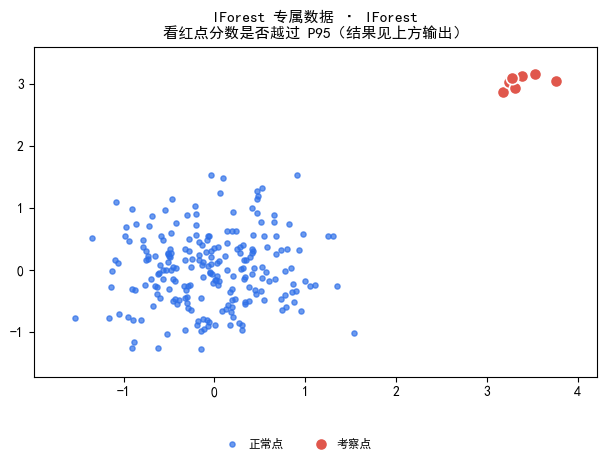

(array([-3.85492142e-02, -7.03534650e-02,  7.49133921e-02, -1.41508278e-01,
        -1.25344287e-01, -3.58027611e-02, -4.47896841e-02, -2.83045678e-02,
        -1.04801802e-01, -5.24168873e-02, -7.62569022e-02, -1.76973017e-02,
        -7.95493136e-02, -1.40658137e-01, -4.42955539e-02, -1.31208131e-01,
        -1.27820381e-01, -2.24027263e-02, -8.56572051e-02, -1.08007370e-01,
        -1.02216617e-01,  1.69016340e-02, -6.23883471e-02, -1.44452041e-01,
        -2.87942676e-02, -1.00013137e-01, -1.34696089e-01, -1.12329562e-01,
         2.09374219e-02, -1.29430751e-01, -7.79113656e-02,  4.80045835e-02,
        -2.59369540e-02, -1.25128695e-01, -1.18662928e-01, -1.03951175e-01,
        -1.04151221e-01, -9.05628000e-02, -9.13282035e-02, -8.96814236e-02,
        -6.04325752e-02, -1.38290491e-02, -8.40722434e-02, -1.26772874e-01,
        -9.98307445e-02, -5.64673649e-02, -1.34308751e-01, -9.94202333e-02,
        -7.43493613e-02, -1.25404965e-01, -5.94589358e-02, -1.32305014e-01,
        -9.0

In [12]:
# --- IForest · 专属数据实验（远处抱团小簇）---
from pyod.models.iforest import IForest                         # Ⅲ 族：孤立森林

m = IForest(n_estimators=100,                                   # 100 棵树
            max_samples=128,                                    # 每棵抽 128 个样本
            random_state=42)                                    # 固定种子 → 结果可复现
diagnose(m, 'IForest', 'IForest', plot=True)                    # 训练 + 打分 + 画图

### 3.2 LODA (Lightweight Online Detector of Anomalies)
> 🧭 **主线定位**：正常 = *不定义*｜分数 = 随机投影直方图似然｜**全族总破口**：偏离度量靠手工 → Ⅳ 族学出来

> 📌 **归族说明**：LODA 不是树模型。它用「随机投影 + 一维直方图」造弱检测器，再用集成把它们平均起来 —— 密度估计来自 Ⅰ 族，随机集成来自 Ⅲ 族，是全章唯一横跨两族的算法。

**🧠 核心原理深度解析**：

LODA 与 iForest 是**同一族（随机化 + 集成）下的两条不同路线**：iForest 随机切分特征轴，LODA 随机选投影方向；两者的共同点是「不做全局距离计算、靠多次随机化取平均」，而不是「一个是另一个的简化版」。

1. **随机投影**：不同于 iForest 的特征轴平行分割，LODA 生成一组随机向量 $w$，将高维数据投影到一维空间 $z = w^T x$。
2. **直方图估计**：对每个投影维度 $z$，构建直方图来估计其概率密度。
3. **对数似然求和**：异常分数是所有投影维度上对数概率密度的平均值（或总和）。
   $$ Score(x) = \frac{1}{M} \sum_{m=1}^{M} \log P_m(w_m^T x) $$

**💡 特点**：
- **推理极快**：只需矩阵乘法 + 查表，非常适合嵌入式设备或高频实时场景。
- **批量模式**：PyOD 目前的实现不支持在线增量更新（partial_fit），尽管原论文提出了相关概念。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.LODA.原理图解.html" target="_blank">👉 在浏览器打开 LODA原理图解</a>](http://127.0.0.1:5500/html/PyOD.LODA.原理图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：正常点是各向同性的高斯团；考察点取角落点 `(1.8, 1.8)` —— x、y 投影各 1.8σ，单看任何一维都不够可疑。
> - **考什么**：单看 x 或 y 都只是 1.8σ；但它在**每个斜方向**上的投影都偏低概率（对角线约 2.5σ）—— 50 个随机方向的直方图把「处处偏低」累积成高分。
> - **对答案**：对照本节实验输出：方向足够多时该点高于 P95；只有 5 个方向时结论看运气 —— LODA 的投影方向不固定 seed，重跑会变，多跑几次就能看到翻车。


[LODA·专属] LODA        | 正常点 P95=0.059 | 考察点=[0.064] | 高于 P95: 100%


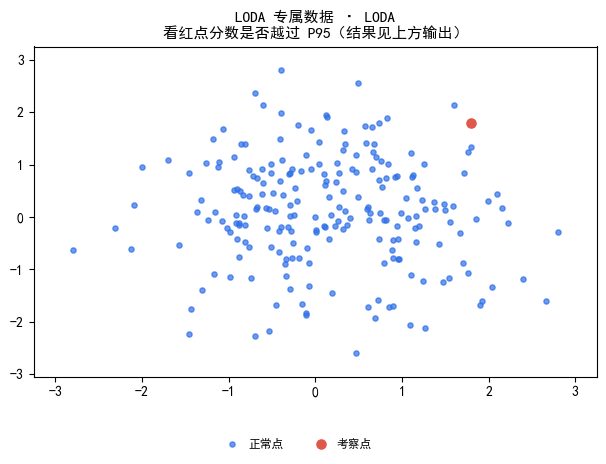

LODA 投影矩阵形状: (50, 2)
非零权重占比: 50.0% → 稀疏投影实现隐式特征选择
[LODA·专属] LODA(5 cuts) | 正常点 P95=0.617 | 考察点=[0.779] | 高于 P95: 100%


(array([0.32575892, 0.37468214, 0.35467027, 0.46191335, 0.65055081,
        0.39614326, 0.38728956, 0.43748281, 0.5741099 , 0.379953  ,
        0.37595217, 0.51906422, 0.37468214, 0.43748281, 0.39614326,
        0.379953  , 0.60133921, 0.58514895, 0.37595217, 0.39614326,
        0.42507621, 0.45367307, 0.32975975, 0.37595217, 0.35849188,
        0.55264878, 0.51103739, 0.33320915, 0.35066943, 0.61295052,
        0.43310304, 0.47258417, 0.32575892, 0.49463368, 0.41564275,
        0.41220008, 0.49725997, 0.45367307, 0.41220008, 0.41220008,
        0.4759445 , 0.46791767, 0.55986622, 0.5349557 , 0.51354479,
        0.45367307, 0.42907704, 0.5349557 , 0.45367307, 0.42507621,
        0.61665197, 0.47258417, 0.46791767, 0.35066943, 0.33320915,
        0.55441084, 0.5349557 , 0.47258417, 0.40761592, 0.44706672,
        0.37468214, 0.32575892, 0.5741099 , 0.39214243, 0.64701114,
        0.35467027, 0.32975975, 0.42507621, 0.42907704, 0.35066943,
        0.38728956, 0.37595217, 0.39214243, 0.37

In [13]:
# --- LODA · 专属数据实验（角落点：靠随机投影投票）---
from pyod.models.loda import LODA                               # Ⅲ 族：轻量在线异常检测

loda = LODA(n_bins=10, n_random_cuts=50,                        # 10 分箱 × 50 个方向
            contamination=0.05)                                 # 5% 阈值
diagnose(loda, 'LODA', 'LODA', plot=True)                       # 训练 + 打分 + 画图

proj_weights = loda.projections_                                # 投影矩阵：50 方向 × 2 特征
print(f"LODA 投影矩阵形状: {proj_weights.shape}")               # 形状 = (50, 2)
print(f"非零权重占比: {(proj_weights != 0).mean():.1%}"         # 稀疏度
      " → 稀疏投影实现隐式特征选择")                            # 等价于只挑少数特征

diagnose(LODA(n_bins=10, n_random_cuts=5),                      # 方向太少时结论不稳
         'LODA', 'LODA(5 cuts)')                                # 只对比分数，不画图

### Ⅲ 族小结

| | IForest | LODA |
| :--- | :--- | :--- |
| 随机化 | 轴平行切分 | 随机投影（稀疏） |
| 分数 | $2^{-E[h(x)]/c(n)}$ | 投影直方图对数似然均值 |
| 速度 | 训练 $O(t\psi\log\psi)$ | 推理 = 矩阵乘 + 查表，极快 |
| 最适合 | 通用大数据、高维首选 | 高频实时 / 资源受限 / 嵌入式 |
| 注意 | `max_samples=256` 通常已够 | PyOD 目前是**批量模式**，无 `partial_fit` |

**族的共同边界**：随机隔离擅长「全局稀疏的异常」。若异常是相对某个局部密集簇而言的，请回到 Ⅱ 族；若需要模型自己学出复杂非线性结构，进入 Ⅳ 族。

---

> 🔗 **回到主线**：本族共同破口是「偏离度量靠手工定义」→ **Ⅳ 族**让模型自己学出正常。


## 第四族｜边界与重构：异常 = 学不会 / 还原不了
> 🧭 **主线进度**：`Ⅰ ─→ Ⅱ ─→ Ⅲ ─→ Ⅳ` 当前 **第 Ⅳ 环（终点）**｜本族把 $\mathcal{M}_{normal}$ 定义成「**学出来的紧凑边界 / 低维流形**」｜补上 Ⅲ 族「度量靠手工」的短板，主线到此闭环。

### 族导语：让模型自己学出「正常」

前三族的偏离度量是人手工定义的（概率、距离、路径长度）。Ⅳ 族把它交给优化过程：用大量正常样本训练一个模型，让它 **只能表示或还原正常模式**；凡是不符合这个学到的结构的，分数就高。

| 两条技术路线 | 学到的是什么 | 分数 |
| :--- | :--- | :--- |
| **显式边界**（OCSVM） | 包住正常样本的最小体积区域 / 分隔超平面 | 到边界的有符号距离 |
| **隐式流形**（PCA / AutoEncoder） | 正常数据所在的低维子空间 / 非线性流形 | 重构误差 $\|x - \hat{x}\|^2$ |

$$
\hat{x} = g(f(x)), \qquad \text{score}(x) = \|x - g(f(x))\|^2
$$

**核心假设**：训练集中**绝大多数是正常样本**，且正常模式存在可被低维结构刻画的共性。若训练数据被大量异常污染，模型会把异常也「学会」，重构误差反而变小 —— 这是本族最隐蔽的失效方式。

> ⚠️ **全族前置动作：必须缩放**。OCSVM 基于核距离，AE 基于梯度与激活函数，二者都对输入尺度敏感；AE 通常用 `MinMaxScaler` 映射到 [0,1]。

**族内递进**：线性边界（OCSVM，核技巧）→ 线性重构（PCA，本系列后续）→ 非线性重构（AutoEncoder）。本章讲首尾两个，中间一个留给第 2 章与 sklearn 对照。

---

### 4.1 OCSVM：给正常数据画一个紧凑的边界
> 🧭 **主线定位**：正常 = 紧凑边界之内｜分数 = 到边界距离｜本节破口：核函数与边界形状靠手工指定 → 4.2 AE 补

> 📌 它是第 2 章「sklearn 原生异常模块」中 `OneClassSVM` 的直接对照。

**🧠 核心原理**：单类分类（One-Class Classification）。没有负样本，只有「正常」这一类，于是换个问法 —— **在特征空间里找一个把原点与正常样本分开的超平面，并让正常样本一侧尽可能紧凑**（Schölkopf 的 OCSVM）；等价地也可理解为 SVDD 找一个包住大部分样本的最小超球。

$$
\min_{w,\rho,\xi}\ \tfrac{1}{2}\|w\|^2 + \frac{1}{\nu n}\sum_i \xi_i - \rho
\quad \text{s.t.}\quad w^\top \phi(x_i) \ge \rho - \xi_i,\ \xi_i \ge 0
$$

1. **核映射** $\phi(\cdot)$：常用 RBF 核，把边界从直线变成弯曲的闭合轮廓。
2. **$\nu$（nu）**：**最关键参数**，同时是「允许落在边界外的训练样本比例上界」与「支持向量比例下界」，可当作「预期异常率」的先验（常取与 `contamination` 接近的值）。
3. **打分**：`decision_function` 给到边界的有符号距离；越靠外越异常，PyOD 已统一成「越大越异常」。

| 优势 | 局限 |
| :--- | :--- |
| 边界严格、对中小数据精度高；`gamma` 可调出很贴合的非线性形状 | $O(n^2\!\sim\!n^3)$、对大样本不友好；**对 $\nu$ 与 $\gamma$ 极敏感**；必须缩放；高维需先降维 |

> 💡 概念对照：OCSVM 学到的「正常区」是一条**光滑闭合的边界**（把环上的正常点整体包住，环心与环外都排除），与 Ⅰ 族的逐维矩形、Ⅱ 族的贴簇几何是三种完全不同的「正常」形状。
>
> 💡 调参提示：`gamma='auto'` 时 RBF 太宽，环心会被一并包进正常区（漏检）；本节显式取 `gamma=1.0` 才能把环心排除 —— 这就是「对 γ 极敏感」的实例。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.OCSVM.原理图解.html" target="_blank">👉 在浏览器打开 OCSVM原理图解</a>](http://127.0.0.1:5500/html/PyOD.OCSVM.原理图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：240 个正常点落在半径 2.6 的细环上，环心是空的；考察点取环心 `(0,0)` 与环外 `(4.2, 0)`。
> - **考什么**：「离均值近 = 正常」的模型会把环心判成最正常，只有 RBF 核学出的紧凑边界能同时围住环、把中心与外圈排除。
> - **对答案**：对照本节实验输出：环心与环外两个考察点应高于 P95，正常点整体低于 P95。


[OCSVM·专属] OCSVM       | 正常点 P95=0.000 | 考察点=[1.119 1.252] | 高于 P95: 100%


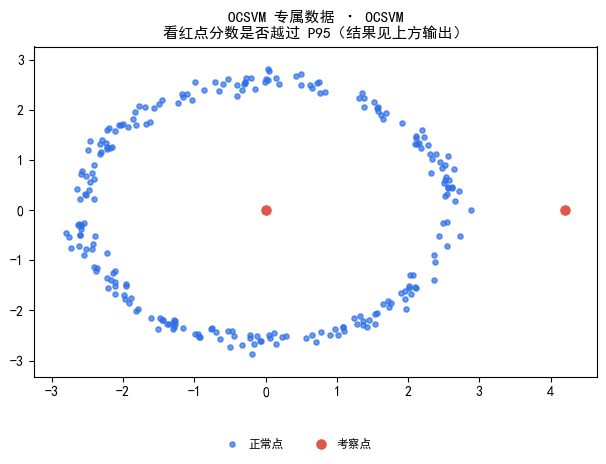

(array([-6.77690473e-02, -3.70289763e-02,  1.26360149e-04, -8.18756942e-02,
        -5.97312940e-02, -4.85079810e-02, -4.89837376e-04, -6.32959869e-02,
        -6.56152516e-02, -6.17220627e-02, -6.79803177e-02, -5.51960229e-02,
        -4.10690656e-02, -1.53302789e-04, -6.99941803e-02, -9.56911571e-02,
        -2.74502680e-02, -6.06369113e-02, -4.42020807e-02, -3.45685818e-02,
        -6.00943717e-02, -6.09290018e-02, -5.97012793e-02, -5.01633068e-02,
        -7.54205502e-02, -7.38663212e-02, -1.85407063e-02, -7.33019907e-02,
        -7.50248942e-02, -6.57978197e-02, -9.54648985e-02, -7.53868180e-02,
        -9.50627722e-02, -1.60396399e-02, -2.87591052e-02,  4.99827073e-04,
        -6.56391515e-02, -6.21713363e-02, -4.18018738e-02, -7.76647205e-02,
        -6.70777114e-02, -9.14348855e-02, -6.84917961e-02, -3.59956209e-02,
        -4.75194179e-02, -6.60359630e-02, -3.85210166e-02, -4.54127758e-02,
         1.30031475e-02, -8.07538853e-02, -2.38080491e-02, -3.67890377e-02,
         2.5

In [14]:
# --- OCSVM · 专属数据实验（环形正常区）---
from pyod.models.ocsvm import OCSVM                             # Ⅳ 族：单类支持向量机

m = OCSVM(kernel='rbf', nu=0.05,                                # RBF 核；nu ≈ 异常占比上界
          gamma=1.0, contamination=0.05)                        # gamma；5% 阈值
diagnose(m, 'OCSVM', 'OCSVM', scale=True, plot=True)            # 标准化 + 画图

### 4.2 AutoEncoder (AE)
> 🧭 **主线定位**：正常 = 低维流形可还原｜分数 = 重构误差｜**主线闭环**：正常模型由数据自己学出

**🧠 核心原理深度解析**：

AE 基于 **重构误差** 原理。神经网络擅长记忆常见的模式，但不擅长记忆罕见的模式。

1. **编码器 (Encoder)**：将输入 $x$ 压缩为一个低维潜在向量 $z$ ($z = Encoder(x)$)。这个过程迫使网络提取最重要的特征。
2. **解码器 (Decoder)**：尝试从 $z$ 还原出原始的 $x'$ ($x' = Decoder(z)$)。
3. **训练目标**：最小化重构损失 $L(x, x')$，通常是均方误差 (MSE)。
   $$ Loss = ||x - Decoder(Encoder(x))||^2 $$
4. **异常检测逻辑**：
   - **正常样本**：网络见过大量类似样本，能很好地编码和解码，重构误差 **小**。
   - **异常样本**：网络没见过这种模式，编码器无法找到合适的潜在表示，或者解码器无法还原细节，导致重构误差 **大**。
5. **异常分数**：直接使用重构误差 $||x - x'||^2$ 作为分数。

**💡 注意事项**：
- **归一化至关重要**：AE 对输入尺度敏感，通常需要将数据缩放到 [0, 1] (MinMaxScaler)。
- **瓶颈层设计**：隐藏层神经元数量应少于输入层，强制网络进行压缩。如果隐藏层太大，网络可能学会恒等映射（Identity Mapping），导致所有样本重构误差都为 0，失效。
- **过拟合风险**：在小数据集上，AE 容易记住噪声。需配合 Dropout 或 Early Stopping。


> 📊 **原理图解 · 展开细看**：[<a href="http://127.0.0.1:5500/html/PyOD.AutoEncoder.原理图解.html" target="_blank">👉 在浏览器打开 AutoEncoder原理图解</a>](http://127.0.0.1:5500/html/PyOD.AutoEncoder.原理图解.html)
**💻 代码实战**

> 🎯 **本节实验 · 专属数据**
> - **题目**：220 个正常点落在 `y = sin(x)` 曲线上（厚 0.07）；考察点为 3 个曲线外的点。
> - **考什么**：瓶颈只有 1 维，只学得会「曲线参数」这一个自由度；曲线外的点无法被低维表示还原，重构误差 ≈ 到曲线的距离。
> - **对答案**：对照本节实验输出：曲线外 3 点的重构误差明显高于正常点 P95。


[AE·专属] AutoEncoder | 正常点 P95=2.194 | 考察点=[2.512 3.471 2.551] | 高于 P95: 100%


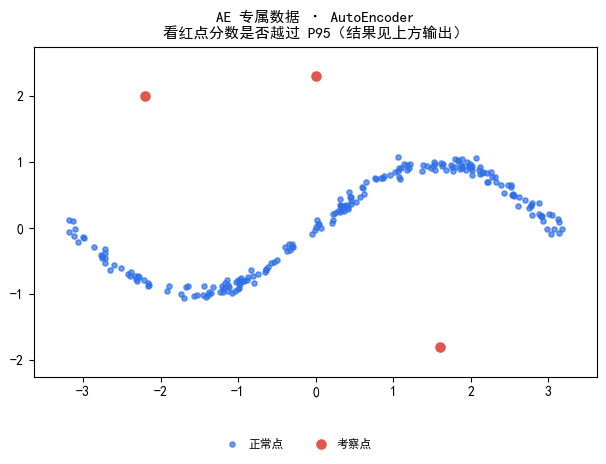

(array([1.0008509 , 0.8413907 , 0.38782364, 2.2757196 , 2.3400655 ,
        1.0427111 , 1.2434747 , 1.2168673 , 1.1749035 , 0.09239435,
        0.12093335, 2.2059822 , 1.9331245 , 0.41924363, 0.08425812,
        1.1459643 , 2.1667078 , 0.22268516, 1.1898869 , 1.2425306 ,
        0.1772932 , 0.1885579 , 1.6199316 , 1.4730598 , 2.1001456 ,
        1.1795591 , 1.9879532 , 0.629599  , 0.71007556, 2.1776907 ,
        0.6831895 , 1.4192326 , 1.2372448 , 2.0890255 , 1.1752774 ,
        1.9772375 , 2.2245586 , 2.0678308 , 2.19055   , 1.2827941 ,
        1.167409  , 1.4496669 , 0.14273384, 1.291045  , 1.2319354 ,
        1.3056163 , 1.3137974 , 1.3442165 , 2.038276  , 1.5114745 ,
        1.6987569 , 0.10876525, 1.2726818 , 1.288466  , 1.5431356 ,
        2.1355546 , 1.3065962 , 1.7650535 , 2.1934807 , 2.0517902 ,
        1.2990316 , 2.0024085 , 1.5044752 , 1.9676944 , 2.269963  ,
        0.5207715 , 2.0362372 , 1.652324  , 0.5375666 , 0.6056282 ,
        2.056217  , 1.1357567 , 1.7894492 , 1.14

In [15]:
# --- AutoEncoder · 专属数据实验（瓶颈 1 维）---
from pyod.models.auto_encoder import AutoEncoder                # Ⅳ 族：自编码器

ae_demo = AutoEncoder(hidden_neuron_list=[2, 1, 2],             # 2→1→2 瓶颈
                      epoch_num=30, batch_size=32,              # 30 轮 / 批 32
                      contamination=0.05, verbose=0)            # 5% / 静默训练
diagnose(ae_demo, 'AE', 'AutoEncoder',                          # 用 AE 专属数据诊断
         scale='minmax', plot=True)                             # MinMax 归一化 + 画图

### Ⅳ 族小结

| | OCSVM | AutoEncoder |
| :--- | :--- | :--- |
| 学什么 | 紧凑边界 | 低维流形（编码器-解码器） |
| 分数 | 到边界距离 | 重构误差 |
| 线性 / 非线性 | 核技巧 → 非线性边界 | 多层网络 → 非线性重构 |
| 规模 | 中小（1W 内） | 中大（GPU 更划算） |
| 主要风险 | $\nu,\gamma$ 敏感 | 瓶颈层过大 → 恒等映射；小数据过拟合 |

**与 Ⅰ 族的对照**：Ⅰ 族逐维相加、看不见组合关系；Ⅳ 族联合建模、能学出数据的整体结构（环、sin 流形）。这就是「独立假设」与「联合结构」的分界线。

> 🔗 补充：**PCA** 位于两者之间（线性重构，$\text{score}=\|x - WW^\top x\|^2$），第 2 章会与 sklearn 的同类实现对照。

---

> 🔗 **主线闭环**：四族合起来就是「$\mathcal{M}_{normal}$ 的四种定义」。从「假设正常长什么样」走到「让模型学出正常」，选型见附录 D。


---

## 附录（**不属于主线**，查 API / 做工程时再看）

> 四族正文到此结束。下面全部**不是新的「正常模型」**，因此不参与主线推进，只按需查阅。
> 下文 A~F 均属本节之下；正文中若出现「A 融合 / D 选型」，指的就是这里的附录 A / 附录 D。


### 附录 · 工具箱速查（完整版：61 个检测器的模块地图）

> 0.0 已介绍 PyOD 的定位、统一接口与 7 类地图的**简版**；本节是**完整查询表**，做工程 / 查 API 时再看。

- **安装**：`pip install pyod`；图 / 音频另装 `pyod[graph]` / `pyod[audio]`。

**官方模块地图（按实现机制，查 API 用）**：

| 官方 Type | 代表算法 |
| :--- | :--- |
| `Probabilistic` | ECOD、COPOD、ABOD、MAD、SOS、QMCD、KDE、GMM |
| `Linear Model` | PCA、KPCA、MCD、CD、OCSVM、LMDD |
| `Proximity-Based` | kNN / AvgKNN / MedKNN、LOF、COF、CBLOF、LOCI、HBOS、SOD、ROD |
| `Outlier Ensembles` | IForest、INNE、DIF、Feature Bagging、LSCP、LODA、XGBOD*、SUOD* |
| `Neural Networks` | AutoEncoder、VAE、DeepSVDD、SO_GAAL / MO_GAAL、AnoGAN、ALAD、DevNet |
| `Graph-based` / `Embedding-based` | R-Graph、LUNAR / EmbeddingOD |
| `pyod.models.combination` | `average` / `maximization` / `AOM` / `MOA` / `median` / `majority vote`（**不是检测器**） |

\* XGBOD 需标签、SUOD 是加速框架。官方先按**数据模态**分 Tabular / Time Series / Graph / Audio 四块；本章只在 Tabular 内。

- **两大功能组**：`Detection Algorithms` **产出分数**（本章四族）；`Utility Functions` **不算分数**，只做造数据、评估、归一化、融合、切标签、持久化等配套。

> 💡 **无监督为什么还分训练 / 测试集**：`fit` 从不接触标签（这才是无监督）；带标签的合成数据只是**离线考卷**，用来科学比较算法。上线后没有 `roc_auc_score`，改用人工抽检、稳定性分析或下游代理指标。

---


### 附录 A · 分数融合（Combination）：让四族各出一员

单一模型总有偏差。PyOD 提供多种分数融合策略。**融合前必须 `standardizer` 归一化！**（各家的分数量纲完全不同：负对数似然、距离、路径长度、重构误差，直接相加等于让尺度最大的那个模型独裁。）

> 📌 **为什么需要一份公共基准数据**：融合要求所有基模型在**同一份数据**上打分，否则分数不可比 —— 这是公共基准数据存在的唯一理由。本节让四个基模型全部在公共基准数据上训练、对同一份 `X_test` 打分，且恰好**每族出一员**，用来演示「跨族互补」：
> Ⅰ 族 ECOD（分布尾部） · Ⅱ 族 KNN（局部距离） · Ⅲ 族 IForest（随机隔离） · Ⅳ 族 AutoEncoder（重构误差）。
> ⚠️ 注意：每个基模型仍用**它自己正文约定的预处理**（KNN 用 RobustScaler、AE 用 MinMaxScaler），只是数据同源。

| 策略 | 公式直觉 | 特点 |
| :--- | :--- | :--- |
| `average` | 均值 | 平滑噪声，最稳健，适合作为默认 |
| `maximization` | 取最大 | 对任一模型强信号敏感，高召回，易误报 |
| `aom` | 分组取 max 再平均 | 平衡灵敏度与稳定性 |
| `moa` | 分组取 avg 再取 max | 相对保守，低误报 |

> ⚠️ AOM / MOA 在 static 模式下要求模型数能被 `n_buckets` 整除。

=== 集成策略 AUC 对比（公共基准数据）===
Average              | AUC: 1.0000
Maximization         | AUC: 0.9974
AOM (buckets=2)      | AUC: 1.0000
MOA (buckets=2)      | AUC: 0.9979


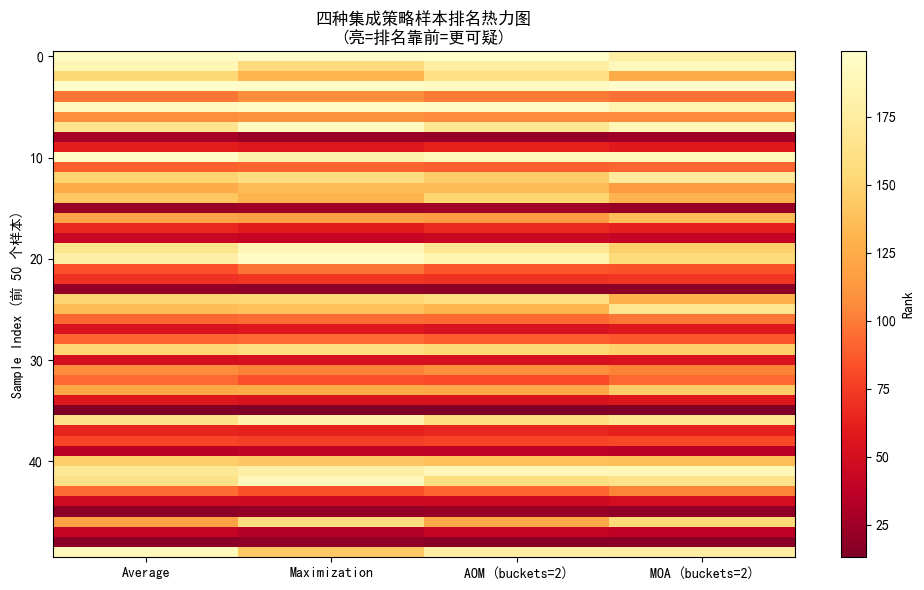

In [16]:
# --- 附录 A：四个基模型各自训练，再融合打分 ---
from sklearn.metrics import roc_auc_score                       # AUC 评估指标
from sklearn.preprocessing import RobustScaler                  # KNN 用：抗离群缩放
from sklearn.preprocessing import MinMaxScaler                  # AE 用：归一化
from pyod.models.ecod import ECOD                               # Ⅰ 族基模型
from pyod.models.knn import KNN                                 # Ⅱ 族基模型
from pyod.models.iforest import IForest                         # Ⅲ 族基模型
from pyod.models.auto_encoder import AutoEncoder                # Ⅳ 族基模型
from pyod.models.combination import average                     # 融合：简单平均
from pyod.models.combination import maximization                # 融合：取最大
from pyod.models.combination import aom, moa                    # 融合：分桶平均 / 取最大
from pyod.utils.utility import standardizer                     # 分数标准化工具

rs = RobustScaler().fit(X_train)                                # KNN 的缩放器
mm = MinMaxScaler().fit(X_train)                                # AE 的缩放器

ecod_a = ECOD(contamination=0.05).fit(X_train)                  # Ⅰ 原始尺度
knn_a = KNN(n_neighbors=10, contamination=0.05)                 # Ⅱ 10 近邻
knn_a.fit(rs.transform(X_train))                                # Robust 缩放后训练
iforest_a = IForest(n_estimators=200, max_samples=256,          # 200 棵树
                    contamination=0.05,                         # 5% 阈值
                    random_state=42).fit(X_train)               # 固定种子
ae_a = AutoEncoder(hidden_neuron_list=[2, 1, 2],                # 2→1→2 瓶颈
                   epoch_num=30, batch_size=32,                 # 30 轮 / 批 32
                   contamination=0.05, verbose=0)               # 5% / 静默
ae_a.fit(mm.transform(X_train))                                 # MinMax 缩放后训练

base_scores = np.column_stack([                                 # 按列拼成 n×4 分数矩阵
    ecod_a.decision_function(X_test),                           # Ⅰ 原始尺度
    knn_a.decision_function(rs.transform(X_test)),              # Ⅱ Robust
    iforest_a.decision_function(X_test),                        # Ⅲ 原始尺度
    ae_a.decision_function(mm.transform(X_test)),               # Ⅳ MinMax
])
norm_scores = standardizer(base_scores)                         # ⚠️ 融合前必须 z-score

results = {                                                     # 每种策略 → 融合后的测试分数
    'Average': average(norm_scores),                            # 简单平均
    'Maximization': maximization(norm_scores),                  # 取最大
    'AOM (buckets=2)': aom(norm_scores, n_buckets=2),           # 分桶平均再取最大
    'MOA (buckets=2)': moa(norm_scores, n_buckets=2),           # 分桶取最大再平均
}

print("=== 集成策略 AUC 对比（公共基准数据）===")               # 表头
for name, fused in results.items():                             # 逐策略评估
    auc = roc_auc_score(y_test, fused)                          # 融合分数 → AUC
    print(f"{name:20s} | AUC: {auc:.4f}")                       # 逐行打印结果

fig, ax = plt.subplots(figsize=(10, 6))                         # 新建画布
ranks = [np.argsort(np.argsort(-v)) for v in results.values()]  # 转排名
rank_matrix = np.column_stack(ranks)                            # 拼成 n×4 排名矩阵
im = ax.imshow(rank_matrix[:50, :], aspect='auto',              # 只看前 50 个样本
               cmap='YlOrRd_r')                                 # 红=排名靠前=更可疑
ax.set_xticks(range(len(results)))                              # x 轴刻度：4 种策略
ax.set_xticklabels(results.keys(), fontsize=10)                 # 刻度标签
ax.set_ylabel('Sample Index (前 50 个样本)')                    # y 轴说明
ax.set_title('四种集成策略样本排名热力图'                       # 标题第 1 段
             '\n(亮=排名靠前=更可疑)',                          # 标题第 2 段
             fontweight='bold')                                 # 标题加粗
plt.colorbar(im, ax=ax, label='Rank')                           # 颜色条：Rank 含义
plt.tight_layout()                                              # 收紧排版
plt.show()                                                      # 渲染

### 附录 B · utils 工具链

#### B.1 数据生成器

两个生成器解决同一个问题：**真实业务没标签，先用已知答案的合成数据把算法掰开看**。

- **`generate_data`**
  - 正常点 = 多元高斯，异常点 = 均匀分布。
  - 返回带隐藏标签的 `X_train, X_test, y_train, y_test`。
  - 本章公共基准数据的来源。
- **`generate_data_clusters`**
  - 直接生成多密度、多簇大小的数据。
  - 用 `size='different', density='different'` 直接生成多密度、多簇大小的数据（与 KNN / LOF / CBLOF 专属数据同类的形状）。

> ⚠️ **返回值与版本差异**
>
> - 默认返回 **4 个数组**：`X_train, X_test, y_train, y_test`。
> - 源码由 `train_test_split` 产生，与 `generate_data` 默认顺序一致。
> - 按 2 个变量解包会抛 `ValueError`。
> - readthedocs 的 Returns 段写成 `X_train, y_train, X_test, y_test`，与源码顺序不一致。
> - 下面代码加了 shape 断言：顺序有变会**立刻报错**，而不是静默把标签当特征画进散点图。

多簇训练集: (500, 2), 异常率: 5.2%


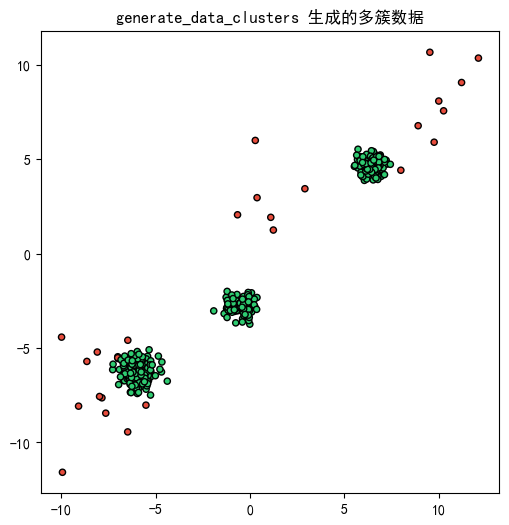

In [17]:
# --- 演示多簇数据生成器（多密度 / 多簇大小）---
from pyod.utils.data import generate_data_clusters              # 多簇数据生成器

(X_clust, X_clust_test,                                         # 训练集
 y_clust, y_clust_test) = generate_data_clusters(               # 测试集与标签
    n_train=500, n_test=100, n_clusters=3,                      # 3 簇
    size='different', density='different',                      # 大小 / 密度都不同
    contamination=0.05, random_state=42)                        # 5% 异常率

assert X_clust.ndim == 2 and y_clust.ndim == 1, (               # 防呆：确认返回顺序
    "返回顺序与预期不符：请 print 各变量 shape"                 # 提示信息第 1 段
    "确认当前 PyOD 版本的返回顺序")                             # 提示信息第 2 段

print(f"多簇训练集: {X_clust.shape},"                           # 形状
      f" 异常率: {y_clust.mean():.1%}")                         # 异常占比

plt.figure(figsize=(6, 6))                                      # 正方形画布
plt.scatter(X_clust[:, 0], X_clust[:, 1],                       # 前两维坐标
            c=y_clust, s=20,                                    # 按标签着色 / 点大小
            cmap=ListedColormap(['#2ecc71', '#e74c3c']),        # 绿正常红异常
            edgecolors='k')                                     # 黑描边，点更清楚
plt.title('generate_data_clusters 生成的多簇数据',              # 标题
          fontweight='bold')                                    # 加粗
plt.gca().set_aspect('equal', adjustable='box')                 # 横纵等比例
plt.show()                                                      # 渲染

#### B.2 评估工具

`evaluate_print(clf_name, y, scores)` 定义在 `pyod.utils.data`，一键打印两项指标：

- **ROC-AUC**：衡量整体排序能力。
- **Precision @ Rank n**：分数最高的前 n 条交给人工复核时，里面真有几条异常。
  - 更贴近真实业务（复核预算有限）。
- **底层**：`pyod.utils.utility.precision_n_scores` 先调 `get_label_n` 把 top-n 置 1，再算 precision。

> ⚠️ `y` 只用于评估、绝不喂给 `fit`；且必须与 scores 来自**同一份数据**（见 0.3 的数据约定）。

In [18]:
# --- 使用 evaluate_print 快速评估 ---
from pyod.utils.data import evaluate_print                      # 在 data 模块里

scores = iforest_a.decision_function(X_test)                    # 用模型给测试集打分
evaluate_print('IForest', y_test, scores)                       # 一行输出 AUC / P@n

IForest ROC:1.0, precision @ rank n:1.0


### 附录 C · 工程化能力

#### C.1 模型持久化 (Save/Load)

持久化有三种写法，别照抄老教程：

- **全版本通用**：`joblib` 或 `pickle` 保存 fitted 检测器（README 官方做法）。
- **PyOD 3 推荐**：`pyod.utils.persistence.save/load`，写入依赖版本与时间戳，便于跨环境排查。
- **已失效**：`from pyod.utils.utility import save_model, load_model` 在 PyOD 3 中已不存在，照抄会 `ImportError`。
- **下面演示**：用 `joblib`。

In [19]:
# --- 演示模型保存与加载（joblib，全版本通用）---
import os                                                       # 文件操作：查大小 / 删除
import joblib                                                   # 模型序列化库

joblib.dump(iforest_a, 'iforest_model.joblib')                  # 训练好的模型存盘
size = os.path.getsize('iforest_model.joblib')                  # 读文件字节数
print(f"✅ 模型已保存: {size} bytes")                           # 确认落盘

loaded_model = joblib.load('iforest_model.joblib')              # 从磁盘加载
new_scores = loaded_model.decision_function(X_test)             # 用加载的模型打分
auc = roc_auc_score(y_test, new_scores)                         # 验证分数是否一致
print(f"✅ 加载验证 AUC: {auc:.4f}")                            # 打印验证结果

os.remove('iforest_model.joblib')                               # 清理演示文件

# PyOD 3 可选：带依赖版本信封的持久化
# from pyod.utils.persistence import save, load
# save(iforest, 'iforest_model.pkl'); loaded = load('iforest_model.pkl')

✅ 模型已保存: 1827863 bytes
✅ 加载验证 AUC: 1.0000


#### C.2 Sklearn Pipeline 集成
PyOD 完美兼容 sklearn Pipeline，实现预处理+检测一体化：

In [20]:
# --- 演示 Sklearn Pipeline 集成 ---
from sklearn.pipeline import Pipeline                           # Sklearn 管线工具

pipe = Pipeline([                                               # 两步串联：缩放 → 检测
    ('scaler', RobustScaler()),                                 # 第 1 步：Robust 缩放
    ('detector', LOF(n_neighbors=20, contamination=0.05))       # 第 2 步：LOF
])

pipe.fit(X_train)                                               # 整条管线一起训练
pipe_scores = pipe.decision_function(X_test)                    # 整条管线一起打分
auc = roc_auc_score(y_test, pipe_scores)                        # 管线分数 → AUC
print(f"Pipeline LOF AUC: {auc:.4f}")                           # 打印评估结果
print("✅ Pipeline 支持 fit/decision_function/predict 全流程")  # 结论

Pipeline LOF AUC: 0.8263
✅ Pipeline 支持 fit/decision_function/predict 全流程


### 附录 D · 选型矩阵：把四族主线收成一张决策表

> 读表顺序建议：**先按「你的数据长什么样」定位族，再在族内挑算法**，而不是在 11 行里平铺着挑。

| 族 | 算法 | 复杂度 | 高维 | 可解释 | 规模上限(CPU) | 缩放 | 最佳场景 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Ⅰ 分布** | ECOD | $O(nd)$ | ⭐⭐⭐⭐ | ⭐⭐⭐ | 100W+ | ❌ | **首选 Baseline**，零调参 |
| **Ⅰ 分布** | HBOS | $O(nd)$ | ⭐⭐⭐⭐ | ⭐⭐⭐⭐⭐ | 100W+ | ❌ | 指标监控 / 根因归因 |
| **Ⅱ 邻近** | KNN | $O(n^2d)$ | ⭐ | ⭐⭐⭐⭐ | 5W | ✅Robust | 小数据、低维、密度均匀 |
| **Ⅱ 邻近** | LOF | $O(n^2d)$ | ⭐ | ⭐⭐⭐ | 5W | ✅Robust | 多密度簇 |
| **Ⅱ 邻近** | COF | $O(n^2d)$ | ⭐⭐ | ⭐⭐⭐ | 3W | ✅Robust | 流形 / 链状数据 |
| **Ⅱ 邻近** | CBLOF | $O(nk)$ | ⭐⭐⭐ | ⭐⭐⭐⭐ | 50W | ✅Robust | 簇大小差异大、需要比 LOF 快 |
| **Ⅱ 邻近** | SOD | $O(n^2d)$ | ⭐⭐⭐⭐ | ⭐⭐ | 3W | ✅Robust | 高维子空间异常 |
| **Ⅲ 隔离** | IForest | $O(t\psi\log\psi)$ | ⭐⭐⭐⭐⭐ | ⭐⭐⭐ | 100W+ | ❌ | **通用大数据 / 高维首选** |
| **Ⅲ 隔离** | LODA | $O(nd)$ | ⭐⭐⭐⭐ | ⭐⭐ | 100W+ | ❌ | 高频实时 / 资源受限 |
| **Ⅳ 边界/重构** | OCSVM | $O(n^2\!\sim\!n^3)$ | ⭐⭐⭐ | ⭐⭐ | 1W | ✅Std | 中小数据、严格非线性边界 |
| **Ⅳ 边界/重构** | AE | $O(E\cdot nd)$ | ⭐⭐⭐⭐⭐ | ⭐⭐ | 10W(GPU) | ✅MinMax | 复杂非线性、特征强相关 |

**一句话决策树**：

1. 数据 > 50W 或维度 > 20 → **Ⅲ 族**（IForest / LODA）；要可解释再加 **Ⅰ 族**（ECOD/HBOS）做归因。
2. 数据小、密度不均匀 / 有流形 → **Ⅱ 族**（LOF / COF）。
3. 特征强相关、异常体现在「组合关系」上 → **Ⅳ 族**（AE）；Ⅰ 族在这种情况下必然失效。
4. 只是想要一个可靠的起点 → **ECOD**，再拿它当 Baseline 与其他族做 A/B。

---

### 附录 E · 工程踩坑清单（按「哪条假设被破坏」归类）

| # | 坑 | 属于哪族 | 原理上的原因 |
| :--- | :--- | :--- | :--- |
| 1 | `contamination` 不是真理，仅影响 `predict()` 阈值 | 全族 | 它只切分位数，不改变 `decision_function()` 的排序 |
| 2 | 分数不可直接相加，集成前必须 `standardizer` | A 融合 | 各族分数量纲不同（似然 / 距离 / 路径 / 误差） |
| 3 | 忘了缩放 → 距离类全错 | Ⅱ、Ⅳ | 距离与核函数对量纲敏感；Ⅰ、Ⅲ 不需要 |
| 4 | 高维禁用 KNN / LOF / COF | Ⅱ | 维度灾难：近邻距离趋于相等 |
| 5 | 两套数据 / 两个 scaler 混用后融合 | A 融合 | 分数不是同一分布下的量，不可比 |
| 6 | AE 隐藏层太宽 → 学到恒等映射 | Ⅳ | 瓶颈不存在时重构误差恒为 0 |
| 7 | AE 输出激活与缩放不匹配 | Ⅳ | MinMax 配 sigmoid，Standard 配 linear |
| 8 | COF 在大样本上逐点打分极慢 / 内存爆 | Ⅱ | $O(n^2)$ 算法对样本数极敏感 |
| 9 | AOM / MOA 报整除错误 | A 融合 | static 模式下模型数必须被 `n_buckets` 整除 |
| 10 | 训练集被异常污染 → AE / OCSVM 失效 | Ⅳ | 模型把异常也当成正常模式学会了 |
| 11 | 时序数据直接套 PyOD | 全族 | 本章针对表格点异常；时序请用 ADTK / River |
| 12 | COF / SOD 只给一两个点调 `decision_function` → `IndexError` | Ⅱ | PyOD 实现按「传入集合」找近邻，须整批打分（`diagnose` 的 `joint=True`） |

---

### 附录 F · 思考题（按族对应，检验主线是否真的建立）

1. **【Ⅰ vs Ⅱ】** 正文的 ECOD 专属数据是一团中等相关的椭圆云；请把相关系数拉高（如 $x_2 = 0.95x_1 + \varepsilon$，变成一条细带），再放一个「每维都不极端但组合反常」的点，看 ECOD / HBOS 的盲区是否更明显。KNN / LOF 呢？请用两节的实验输出解释「逐维独立打分」与「几何关系打分」的差异。
2. **【Ⅱ 族内部】** 在 KNN 专属数据（双密度簇）上把 `n_neighbors` 从 5 调到 50，观察稀疏簇正常点的分数如何变化；再用 LOF 跑**同一份数据**（`diagnose(LOF(n_neighbors=20), 'KNN', 'LOF@KNN数据', scale=True)` —— 专属数据可以跨算法复用）。说明「绝对距离」与「相对密度」的差别。
3. **【维度灾难】** 把 KNN 与 IForest 分别跑在 SOD 的 10 维专属数据上（`diagnose(KNN(n_neighbors=20), 'SOD', ...)` 与 `diagnose(IForest(...), 'SOD', ...)`），比较两者对「考察点」的打分，验证 Ⅱ→Ⅲ 的递进理由。
4. **【Ⅲ 族桥梁】** LODA 的 `projections_` 非零占比很低。为什么说它是「Ⅰ 族直方图 + Ⅲ 族随机集成」的混血？把 `n_random_cuts` 从 50 降到 5，打分结论会怎样变化？
5. **【Ⅳ 族】** 把 AutoEncoder 的 `hidden_neuron_list` 设为 `[2]`（极度压缩），观察实验输出，解释「过度压缩导致正常样本也被判异常」；再设为 `[64, 32, 32, 64]`，观察恒等映射风险。
6. **【A 融合】** 若某个真实异常在 `Maximization` 下排名 Top1、在 `Average` 下排名 Top50，说明什么？它更可能是哪一族擅长、哪一族漏掉的类型？该选哪种策略？
7. **【D 选型】** 500 个传感器、每秒 1000 条、特征强相关、需实时告警。请按「先定族、再定算法」的顺序给出组合并说明理由。

---

> 📌 **下一章预告**：第 2 章 Scikit-learn 原生异常模块
>
> - **做法**：用相同可视化套件对比 sklearn 与 PyOD 同名实现的决策边界。
> - **对照**：`OneClassSVM` ↔ 4.1、`IsolationForest` ↔ 3.1、`LocalOutlierFactor` ↔ 2.3、`PCA` 重构 ↔ Ⅳ 族。
> - **看点**：底层 C/Cython 实现对性能与数值稳定性的影响。
> - **补缺**：本章只一笔带过的**线性重构**一环。